# Continuidad de pistas y lectura con luz variable · Jennifer

Revisar las capturas antes y después de huecos en una pista. Comparar los recortes originales con los ajustes de brillo y perspectiva cuando el módulo los aplique.

Al volver a ejecutar en Colab, selecciona GPU y sube los videos asignados, el detector de placas y el clasificador visual de estados. El clasificador de marca se descarga desde su versión fijada. El análisis usa 15 fotogramas por segundo y un lado máximo de 1920 px. La búsqueda de placas se hace cada dos cuadros de análisis.


El clasificador de marca registra etiquetas crudas con sus puntuaciones. Las predicciones por debajo de 0,65 quedan marcadas como de baja confianza. Estado visual usa el diseño de las placas de referencia y deja valores vacíos cuando la evidencia es insuficiente.


In [1]:
PAQUETES = 'ultralytics lap easyocr fast-plate-ocr[onnx] imageio-ffmpeg onnxruntime pypdf'

import importlib.util
import os
import subprocess
import sys
from pathlib import Path

def ejecutar(*argumentos):
    proceso = subprocess.run(argumentos, capture_output=True, text=True, encoding='utf-8', errors='replace')
    if proceso.stdout:
        print(proceso.stdout, end='')
    if proceso.stderr:
        print(proceso.stderr, end='', file=sys.stderr)
    proceso.check_returncode()

if importlib.util.find_spec('google') and importlib.util.find_spec('google.colab'):
    ejecutar(sys.executable, '-m', 'pip', 'install', '-q', *PAQUETES.split())
print('Python', sys.version.split()[0])


Python 3.12.10


## Detector, seguimiento y lectura


In [2]:
Path('config').mkdir(exist_ok=True)


In [3]:
%%writefile config/bytetrack_mx.yaml
# ByteTrack ajustado para tráfico vehicular (Ultralytics).
# track_buffer alto = el ID sobrevive ~3 s a 30 fps cuando el vehículo pasa detrás
# de un poste o de otro vehículo más grande. modulo_vision.py además re-une
# fragmentos si el tracker llegara a asignar un ID nuevo tras la oclusión.
tracker_type: bytetrack
track_high_thresh: 0.25   # umbral para la primera asociación
track_low_thresh: 0.1     # umbral para la segunda asociación (detecciones débiles, p. ej. parcialmente ocultas)
new_track_thresh: 0.35    # confianza mínima para abrir una pista nueva (evita IDs fantasma)
track_buffer: 45          # cuadros que se conserva una pista perdida antes de borrarla
match_thresh: 0.8         # umbral de asociación
fuse_score: True


Overwriting config/bytetrack_mx.yaml


In [4]:
%%writefile modulo_vision.py
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
modulo_vision.py — Etapa 1: Extracción visual y seguimiento de vehículos.

Recibe una imagen, una carpeta de imágenes o un video y, para cada vehículo único:
  * Detecta el vehículo y su tipo (YOLOv8) y, en video, le asigna un ID estable
    (ByteTrack + fusión de fragmentos tras oclusiones).
  * Guarda la mejor toma del vehículo  -> data/crops/vehiculo_{ID}.jpg
  * Localiza la placa, la rectifica (perspectiva), ajusta brillo/contraste y la
    guarda en alta resolución          -> data/crops/placa_{ID}.jpg
  * Clasifica marca/modelo (red entrenada con entrenar_clasificador.py).
  * Clasifica el estado emisor de la placa SOLO por su apariencia visual
    (colores, escudo, diseño) con otra red entrenada.
  * Lee todo el texto visible de la placa con OCR (PaddleOCR > EasyOCR > Tesseract).
  * Dibuja recuadros/IDs/etiquetas      -> output/video_procesado.mp4 | imagen_procesada.jpg
  * Respalda todo                       -> output/1_vision_crudo.json

Uso rápido:
    python modulo_vision.py ruta/a/video.mp4
    python modulo_vision.py ruta/a/foto.jpg --raiz evidencias/01_tres_tipos
    python modulo_vision.py carpeta_con_fotos/ --clasificador-marcas models/clasificador_marcas.pt

Uso como librería:
    from modulo_vision import procesar
    registros = procesar("avenida.mp4")      # -> list[dict]
"""
from __future__ import annotations

import argparse
import bisect
import json
import logging
import math
import sys
import time
import unicodedata
from collections import deque
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import cv2
import numpy as np

LOG = logging.getLogger("vision")

DIR_SCRIPT = Path(__file__).resolve().parent
EXT_IMAGEN = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
EXT_VIDEO = {".mp4", ".avi", ".mov", ".mkv", ".m4v", ".wmv", ".mpg", ".mpeg"}

# Clases COCO que nos interesan y cómo las nombramos. Con un modelo propio
# (p. ej. entrenado en Roboflow con sedan/suv/pickup/motocicleta/placa) se usan
# directamente los nombres de sus clases.
COCO_VEHICULOS = {"car": "auto", "motorcycle": "motocicleta", "bus": "autobus", "truck": "camion"}
NOMBRES_PLACA = {"placa", "plate", "license_plate", "license-plate", "licence_plate",
                 "licence-plate", "license plate", "matricula", "lp", "number_plate"}

# Colores BGR distintos por tipo de vehículo.
COLORES_TIPO = {
    "sedan": (255, 140, 0),        # azul
    "hatchback": (255, 200, 80),
    "suv": (180, 60, 220),         # morado
    "pickup": (0, 140, 255),       # naranja
    "camioneta": (0, 140, 255),
    "motocicleta": (255, 0, 255),  # magenta
    "autobus": (0, 220, 255),      # amarillo
    "camion": (0, 0, 230),         # rojo
    "van": (160, 160, 0),
}
COLOR_PLACA = (0, 255, 0)

IMAGENET_MEDIA = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


# --------------------------------------------------------------------------- #
# Configuración
# --------------------------------------------------------------------------- #
@dataclass
class Config:
    raiz: Path = Path(".")
    modelo_vehiculos: str = "yolov8n.pt"
    modelo_placas: Optional[str] = str(DIR_SCRIPT / "models" / "placas_yolov8.pt")
    clasificador_marcas: Optional[str] = str(DIR_SCRIPT / "models" / "clasificador_marcas.pt")
    clasificador_estados: Optional[str] = str(DIR_SCRIPT / "models" / "clasificador_estados.pt")
    tracker: str = str(DIR_SCRIPT / "config" / "bytetrack_mx.yaml")
    conf_vehiculo: float = 0.35
    conf_placa: float = 0.25
    imgsz: int = 960
    dispositivo: Optional[str] = None
    min_frames: int = 5               # pistas más cortas se descartan como ruido
    max_seg_oclusion: float = 3.0     # hueco máximo para re-unir un vehículo tras un obstáculo
    capturas: list = field(default_factory=list)  # segundos donde guardar capturas del video
    ocr: str = "auto"                 # auto | paddle | easyocr | tesseract | ninguno
    umbral_conf_log: float = 0.80     # umbral para marcar OK/BAJA en el log de clasificación
    # Falsos positivos estáticos (espectaculares, anuncios o murales con fotos de vehículos):
    # en video se descartan las pistas que casi no se mueven y cuya confianza promedio es baja.
    # Un auto estacionado real suele detectarse con confianza alta y se conserva.
    filtrar_estaticos: bool = True
    conf_min_estatico: float = 0.60   # pistas estáticas con confianza menor a esto se descartan
    mov_min_estatico: float = 0.35    # desplazamiento total < 0.35 × tamaño de su caja = "estático"
    zonas_excluir: list = field(default_factory=list)  # [(x1,y1,x2,y2)] en fracción del cuadro (0-1)

    @property
    def dir_crops(self) -> Path:
        return self.raiz / "data" / "crops"

    @property
    def dir_output(self) -> Path:
        return self.raiz / "output"

    @property
    def dir_evidencias(self) -> Path:
        return self.raiz / "output" / "evidencias"

    @property
    def dir_capturas(self) -> Path:
        return self.raiz / "output" / "capturas"


# --------------------------------------------------------------------------- #
# Utilidades generales
# --------------------------------------------------------------------------- #
def _hms(segundos: float) -> str:
    s = int(max(0, segundos))
    return f"{s // 3600:02d}:{(s % 3600) // 60:02d}:{s % 60:02d}"


def _ascii(texto: str) -> str:
    """cv2.putText no dibuja acentos: los quitamos sólo para la etiqueta en pantalla."""
    return unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")


def _snake(texto: str) -> str:
    t = _ascii(texto).strip().lower()
    for ch in " -/.,()":
        t = t.replace(ch, "_")
    while "__" in t:
        t = t.replace("__", "_")
    return t.strip("_")


def _r(x, n=2):
    return None if x is None else round(float(x), n)


def _rel(ruta: Path, raiz: Path) -> str:
    try:
        return ruta.resolve().relative_to(raiz.resolve()).as_posix()
    except ValueError:
        return ruta.as_posix()


def _color_tipo(tipo: str):
    if tipo in COLORES_TIPO:
        return COLORES_TIPO[tipo]
    h = abs(hash(tipo)) % 180
    hsv = np.uint8([[[h, 220, 255]]])
    return tuple(int(c) for c in cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)[0, 0])


def _recortar(img, caja, pad=0.0):
    """Recorta caja (x1,y1,x2,y2) con margen relativo `pad`, limitado al borde."""
    h, w = img.shape[:2]
    x1, y1, x2, y2 = [float(v) for v in caja]
    pw, ph = (x2 - x1) * pad, (y2 - y1) * pad
    x1, y1 = int(max(0, x1 - pw)), int(max(0, y1 - ph))
    x2, y2 = int(min(w, x2 + pw)), int(min(h, y2 + ph))
    if x2 <= x1 or y2 <= y1:
        return None, (x1, y1, x2, y2)
    return img[y1:y2, x1:x2].copy(), (x1, y1, x2, y2)


def _nitidez(img) -> float:
    if img is None or img.size == 0:
        return 0.0
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    return float(cv2.Laplacian(g, cv2.CV_64F).var())


def _iou(a, b) -> float:
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _ioa(placa, veh) -> float:
    """Fracción del área de la placa que cae dentro del vehículo."""
    ix1, iy1 = max(placa[0], veh[0]), max(placa[1], veh[1])
    ix2, iy2 = min(placa[2], veh[2]), min(placa[3], veh[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area = (placa[2] - placa[0]) * (placa[3] - placa[1])
    return inter / area if area > 0 else 0.0


def _partes_contiguas(a, b) -> bool:
    """¿Son a y b dos mitades del mismo vehículo separadas por un obstáculo vertical delgado?
    Misma franja vertical, alturas parecidas y separación horizontal pequeña."""
    ha, hb = a[3] - a[1], b[3] - b[1]
    if min(ha, hb) <= 0 or min(ha, hb) / max(ha, hb) < 0.7:
        return False
    solape_v = max(0.0, min(a[3], b[3]) - max(a[1], b[1])) / min(ha, hb)
    sep_h = max(a[0], b[0]) - min(a[2], b[2])  # negativa si se enciman
    return solape_v >= 0.7 and sep_h <= 0.6 * max(ha, hb)


def _centro(c):
    return np.array([(c[0] + c[2]) / 2.0, (c[1] + c[3]) / 2.0])


def _hist_hsv(img):
    if img is None or img.size == 0:
        return None
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1], None, [30, 32], [0, 180, 0, 256])
    cv2.normalize(h, h, 0, 1, cv2.NORM_MINMAX)
    return h


def _etiqueta(img, texto, x, y, color, escala=0.6, abajo=False):
    """Dibuja texto con fondo sólido del color de la caja."""
    texto = _ascii(texto)
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 2)
    x = int(max(0, min(x, img.shape[1] - tw - 4)))
    if abajo:
        y0, y1 = int(y), int(y + th + base + 6)
    else:
        y0, y1 = int(y - th - base - 6), int(y)
        if y0 < 0:
            y0, y1 = int(y), int(y + th + base + 6)
    cv2.rectangle(img, (x, y0), (x + tw + 6, y1), color, -1)
    lum = 0.114 * color[0] + 0.587 * color[1] + 0.299 * color[2]
    tcol = (0, 0, 0) if lum > 140 else (255, 255, 255)
    cv2.putText(img, texto, (x + 3, y1 - base - 3), cv2.FONT_HERSHEY_SIMPLEX, escala, tcol, 2, cv2.LINE_AA)


def _panel(img, titulo, alto=320):
    """Escala una imagen a `alto` px y le pone un título encima (para comparativas)."""
    if img is None or img.size == 0:
        img = np.zeros((alto, alto, 3), np.uint8)
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    f = alto / img.shape[0]
    img = cv2.resize(img, (max(1, int(img.shape[1] * f)), alto),
                     interpolation=cv2.INTER_CUBIC if f > 1 else cv2.INTER_AREA)
    barra = np.full((36, img.shape[1], 3), 30, np.uint8)
    cv2.putText(barra, _ascii(titulo)[:80], (8, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return np.vstack([barra, img])


def _comparativa(paneles, ruta: Path):
    sep = np.full((paneles[0].shape[0], 8, 3), 255, np.uint8)
    partes = []
    for p in paneles:
        partes += [p, sep]
    ruta.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(ruta), np.hstack(partes[:-1]))


# --------------------------------------------------------------------------- #
# Pre-procesamiento de la placa (OpenCV)
# --------------------------------------------------------------------------- #
def _ordenar_puntos(pts):
    pts = pts.reshape(4, 2).astype("float32")
    s, d = pts.sum(axis=1), np.diff(pts, axis=1).ravel()
    return np.array([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]], "float32")


def corregir_perspectiva(img):
    """Busca el contorno cuadrilátero de la placa y lo endereza.
    Devuelve (imagen_rectificada, cuadrilatero|None)."""
    if img is None or img.shape[0] < 20 or img.shape[1] < 20:
        return img, None
    h, w = img.shape[:2]
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gris = cv2.bilateralFilter(gris, 9, 30, 30)
    med = float(np.median(gris))  # umbrales adaptativos: funcionan igual con placas claras u oscuras
    bordes = cv2.Canny(gris, max(10, 0.66 * med), max(40, min(255, 1.33 * med)))
    bordes = cv2.dilate(bordes, np.ones((3, 3), np.uint8), iterations=1)
    cnts = cv2.findContours(bordes, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[-2]
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:15]
    for c in cnts:
        peri = cv2.arcLength(c, True)
        aprox = cv2.approxPolyDP(c, 0.03 * peri, True)
        if len(aprox) != 4 or not cv2.isContourConvex(aprox):
            continue
        if cv2.contourArea(aprox) < 0.30 * w * h:
            continue
        tl, tr, br, bl = q = _ordenar_puntos(aprox)
        ancho = max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl))
        alto = max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl))
        if ancho < 10 or alto < 10:
            continue
        # ¿Ya está prácticamente alineada? (todos los lados a < 2.5° de la horizontal/vertical)
        ang_sup = abs(math.degrees(math.atan2(tr[1] - tl[1], tr[0] - tl[0])))
        ang_inf = abs(math.degrees(math.atan2(br[1] - bl[1], br[0] - bl[0])))
        ang_izq = abs(math.degrees(math.atan2(bl[0] - tl[0], bl[1] - tl[1])))
        ang_der = abs(math.degrees(math.atan2(br[0] - tr[0], br[1] - tr[1])))
        if max(ang_sup, ang_inf, ang_izq, ang_der) < 2.5:
            return img, None
        dst = np.array([[0, 0], [ancho - 1, 0], [ancho - 1, alto - 1], [0, alto - 1]], "float32")
        M = cv2.getPerspectiveTransform(q, dst)
        return cv2.warpPerspective(img, M, (int(ancho), int(alto)), flags=cv2.INTER_CUBIC), q
    # Respaldo: si no hay cuadrilátero claro, corrige sólo la rotación del bloque de texto.
    _, th = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    pts = cv2.findNonZero(th)
    if pts is not None and len(pts) > 50:
        (cx, cy), (rw, rh), ang = cv2.minAreaRect(pts)
        if rw < rh:
            ang -= 90
        if 3 <= abs(ang) <= 25:
            M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)
            return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE), None
    return img, None


def ajustar_iluminacion(img, umbral_brillo=95, umbral_contraste=35):
    """Si la placa está oscura o sin contraste: CLAHE + corrección gamma + denoise.
    Devuelve (imagen, se_aplico, brillo_original)."""
    if img is None or img.size == 0:
        return img, False, 0.0
    v = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 2]
    brillo, contraste = float(v.mean()), float(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).std())
    if brillo >= umbral_brillo and contraste >= umbral_contraste:
        return img, False, brillo
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(l)
    out = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
    media = cv2.cvtColor(out, cv2.COLOR_BGR2HSV)[:, :, 2].mean() / 255.0
    if 0.02 < media < 0.45:
        gamma = float(np.clip(math.log(0.5) / math.log(media), 0.3, 1.0))
        lut = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)], np.uint8)
        out = cv2.LUT(out, lut)
    if brillo < umbral_brillo:
        out = cv2.fastNlMeansDenoisingColored(out, None, 6, 6, 7, 21)
        # Al aclarar, los colores quedan deslavados; el color es clave para reconocer el estado.
        hsv = cv2.cvtColor(out, cv2.COLOR_BGR2HSV).astype(np.float32)
        hsv[:, :, 1] = np.clip(hsv[:, :, 1] * 1.4, 0, 255)
        out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)
    return out, True, brillo


def mejorar_resolucion(img, alto_min=160):
    """Escala placas pequeñas (motos, lejanas) y aplica unsharp-mask para que queden nítidas."""
    if img is None or img.size == 0:
        return img
    if img.shape[0] < alto_min:
        f = alto_min / img.shape[0]
        img = cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(img, (0, 0), 1.2)
    return cv2.addWeighted(img, 1.6, blur, -0.6, 0)


def localizar_placa_clasico(crop, es_moto=False):
    """Respaldo sin modelo de placas: morfología blackhat + gradiente.
    Devuelve (x1,y1,x2,y2,conf) en coordenadas del recorte, o None."""
    if crop is None or crop.shape[0] < 40 or crop.shape[1] < 40:
        return None
    gris = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    esc = 480.0 / gris.shape[1] if gris.shape[1] < 480 else 1.0
    if esc != 1.0:
        gris = cv2.resize(gris, None, fx=esc, fy=esc, interpolation=cv2.INTER_CUBIC)
    H, W = gris.shape
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (max(9, W // (18 if es_moto else 22)), max(3, H // 50)))
    bh = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, k)
    gx = np.absolute(cv2.Sobel(bh, cv2.CV_32F, 1, 0, ksize=-1))
    gx = cv2.normalize(gx, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    gx = cv2.morphologyEx(cv2.GaussianBlur(gx, (5, 5), 0), cv2.MORPH_CLOSE, k)
    th = cv2.threshold(gx, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
    th = cv2.dilate(cv2.erode(th, None, iterations=2), None, iterations=2)
    mejor, mejor_s = None, 0.0
    for c in cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]:
        x, y, bw, bh_ = cv2.boundingRect(c)
        ar, rel = bw / max(bh_, 1), (bw * bh_) / (W * H)
        if not ((0.7 <= ar <= 2.6) if es_moto else (1.8 <= ar <= 6.5)):
            continue
        if rel < 0.004 or rel > 0.20:
            continue
        cy, cx = (y + bh_ / 2) / H, (x + bw / 2) / W
        if cy < 0.30 or not (0.1 < cx < 0.9):
            continue
        s = (cv2.contourArea(c) / (bw * bh_)) * (0.5 + cy) * math.sqrt(rel)
        if s > mejor_s:
            mejor, mejor_s = (x, y, x + bw, y + bh_), s
    if mejor is None:
        return None
    x1, y1, x2, y2 = [v / esc for v in mejor]
    return (x1, y1, x2, y2, 0.30)  # confianza fija: es heurístico


# --------------------------------------------------------------------------- #
# Clasificadores (marca/modelo y estado de la placa)
# --------------------------------------------------------------------------- #
def construir_modelo(arquitectura: str, n_clases: int, preentrenado: bool = True):
    """Red de torchvision con la última capa reemplazada (transfer learning).
    Compartida con entrenar_clasificador.py para que entrenamiento e inferencia coincidan."""
    import torch.nn as nn
    from torchvision import models

    w = "DEFAULT" if preentrenado else None
    a = arquitectura.lower()
    if a == "resnet18":
        m = models.resnet18(weights=w); m.fc = nn.Linear(m.fc.in_features, n_clases)
    elif a == "resnet50":
        m = models.resnet50(weights=w); m.fc = nn.Linear(m.fc.in_features, n_clases)
    elif a == "mobilenet_v3_large":
        m = models.mobilenet_v3_large(weights=w); m.classifier[3] = nn.Linear(m.classifier[3].in_features, n_clases)
    elif a == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=w); m.classifier[3] = nn.Linear(m.classifier[3].in_features, n_clases)
    elif a == "efficientnet_b0":
        m = models.efficientnet_b0(weights=w); m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_clases)
    else:
        raise ValueError(f"Arquitectura no soportada: {arquitectura}")
    return m


class ClasificadorImagen:
    """Carga un checkpoint de entrenar_clasificador.py ({arquitectura, clases, state_dict, ...})
    o, como alternativa, un modelo YOLOv8-cls de Ultralytics."""

    def __init__(self, ruta: str, nombre: str, dispositivo=None):
        import torch

        self.nombre, self.ruta = nombre, ruta
        self.torch = torch
        self.dev = torch.device(dispositivo if dispositivo and dispositivo != "cpu" and torch.cuda.is_available()
                                else ("cuda" if dispositivo is None and torch.cuda.is_available() else "cpu"))
        self.yolo = None
        ckpt = None
        try:
            ckpt = torch.load(ruta, map_location="cpu", weights_only=False)
        except Exception:
            pass
        if isinstance(ckpt, dict) and "clases" in ckpt and "state_dict" in ckpt:
            self.clases = list(ckpt["clases"])
            self.tam = int(ckpt.get("tam_imagen", 224))
            self.media = np.array(ckpt.get("media", IMAGENET_MEDIA), np.float32)
            self.std = np.array(ckpt.get("std", IMAGENET_STD), np.float32)
            self.modelo = construir_modelo(ckpt["arquitectura"], len(self.clases), preentrenado=False)
            self.modelo.load_state_dict(ckpt["state_dict"])
            self.modelo.to(self.dev).eval()
        else:
            from ultralytics import YOLO

            self.yolo = YOLO(ruta)
            self.clases = [self.yolo.names[i] for i in sorted(self.yolo.names)]
        LOG.info("Clasificador de %s cargado: %s (%d clases)", nombre, Path(ruta).name, len(self.clases))

    def predecir(self, img_bgr, k=3):
        """Devuelve lista [(clase, prob), ...] ordenada de mayor a menor."""
        if img_bgr is None or img_bgr.size == 0:
            return []
        if self.yolo is not None:
            r = self.yolo.predict(img_bgr, verbose=False)[0]
            p = r.probs.data.cpu().numpy()
        else:
            rgb = cv2.cvtColor(cv2.resize(img_bgr, (self.tam, self.tam), interpolation=cv2.INTER_AREA),
                               cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
            x = ((rgb - self.media) / self.std).transpose(2, 0, 1)[None]
            with self.torch.no_grad():
                logits = self.modelo(self.torch.from_numpy(x).to(self.dev))
                p = self.torch.softmax(logits, dim=1)[0].cpu().numpy()
        orden = np.argsort(-p)[:k]
        return [(self.clases[i], float(p[i])) for i in orden]


# --------------------------------------------------------------------------- #
# OCR
# --------------------------------------------------------------------------- #
def _ordenar_lecturas(lecturas):
    """lecturas: [(caja_poligono Nx2, texto, conf)] -> ordenadas por renglón y luego izquierda→derecha
    (las placas de moto suelen tener 2 renglones)."""
    items = []
    for poly, txt, conf in lecturas:
        p = np.asarray(poly, np.float32).reshape(-1, 2)
        items.append((p[:, 1].mean(), p[:, 0].min(), max(1.0, p[:, 1].max() - p[:, 1].min()), txt, conf))
    items.sort(key=lambda t: t[0])
    renglones = []
    for it in items:
        if renglones and abs(it[0] - renglones[-1][0][0]) < 0.5 * max(it[2], renglones[-1][0][2]):
            renglones[-1].append(it)
        else:
            renglones.append([it])
    salida = []
    for r in renglones:
        salida += sorted(r, key=lambda t: t[1])
    return [(t[3], t[4]) for t in salida]


def _votar_ocr(lecturas):
    """lecturas: [dict de MotorOCR.leer_detalle] (o tuplas (texto, conf)) de varias tomas de la misma placa.
    Agrupa por la serie (o el texto) normalizado a letras/dígitos y elige el grupo con mayor confianza
    acumulada. Devuelve (lectura_más_confiable_del_grupo, confianza_media_del_grupo, nº_de_votos)."""
    grupos = {}
    for lec in lecturas:
        if isinstance(lec, tuple):
            lec = {"texto": lec[0], "conf": lec[1], "serie": None}
        base = lec.get("serie") or lec.get("texto")
        if not base:
            continue
        clave = "".join(ch for ch in base.upper() if ch.isalnum())
        if clave:
            grupos.setdefault(clave, []).append(lec)
    if not grupos:
        return None, None, 0
    clave = max(grupos, key=lambda k: (sum(x["conf"] or 0.0 for x in grupos[k]), len(k)))
    g = grupos[clave]
    mejor = max(g, key=lambda x: x["conf"] or 0.0)
    return mejor, sum(x["conf"] or 0.0 for x in g) / len(g), len(g)


class MotorOCR:
    """OCR en dos niveles:
      * Especializado en placas (fast-plate-ocr, modelo global con 60+ países incl. México): lee la
        SERIE con mucha más precisión que un OCR general y además estima el país/región de la placa.
      * General (PaddleOCR > EasyOCR > Tesseract): lee el resto del texto visible (p. ej. "JALISCO").
    Con preferencia "auto" se usan ambos si están instalados; el texto crudo es serie + texto extra."""

    GENERALES = ["paddle", "easyocr", "tesseract"]
    MODELO_PLACAS = "cct-s-v2-global-model"

    def __init__(self, preferencia="auto"):
        self.nombre, self._motor, self._paddle_v3 = None, None, False
        self._placas = None
        if preferencia in ("auto", "placa"):
            try:
                from fast_plate_ocr import LicensePlateRecognizer
                self._placas = LicensePlateRecognizer(self.MODELO_PLACAS, device="auto")
                LOG.info("OCR de placas: fast-plate-ocr (%s)", self.MODELO_PLACAS)
            except Exception as e:  # noqa: BLE001
                LOG.debug("fast-plate-ocr no disponible: %s", e)
        orden = {"auto": self.GENERALES, "placa": [], "ninguno": []}.get(preferencia, [preferencia])
        for motor in orden:
            try:
                getattr(self, f"_init_{motor}")()
                self.nombre = motor
                LOG.info("OCR general: %s", motor)
                break
            except Exception as e:  # noqa: BLE001 - probamos el siguiente motor
                LOG.debug("OCR %s no disponible: %s", motor, e)
        if self.nombre is None and self._placas is None and preferencia != "ninguno":
            LOG.warning("No hay motor OCR instalado (pip install fast-plate-ocr[onnx] easyocr). "
                        "texto_ocr_crudo quedará en null.")

    def _leer_serie(self, img):
        """Serie de la placa con fast-plate-ocr -> (serie|None, conf|None, region|None, conf_region|None)."""
        if self._placas is None:
            return None, None, None, None
        modo = getattr(self._placas.config, "image_color_mode", "rgb")
        x = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY if modo == "grayscale" else cv2.COLOR_BGR2RGB)
        p = self._placas.run(x, return_confidence=True)[0]
        serie = (p.plate or "").strip()
        if not serie:
            return None, None, None, None
        probs = getattr(p, "char_probs", None)
        conf = float(np.mean(probs[:len(serie)])) if probs is not None and len(probs) else None
        return serie, conf, getattr(p, "region", None), getattr(p, "region_prob", None)

    def leer_detalle(self, img) -> dict:
        """Lectura completa. Nunca lanza excepción. Claves: texto, conf, serie, region, conf_region."""
        r = {"texto": None, "conf": None, "serie": None, "region": None, "conf_region": None}
        if img is None or img.size == 0:
            return r
        try:
            serie, conf_s, region, conf_r = self._leer_serie(img)
        except Exception as e:  # noqa: BLE001
            LOG.warning("Fallo de fast-plate-ocr: %s", e)
            serie = conf_s = region = conf_r = None
        general, conf_g = self.leer(img)
        if serie:
            # Se agrega del OCR general sólo lo que NO es la serie (p. ej. el nombre del estado)
            from difflib import SequenceMatcher
            clave = "".join(ch for ch in serie if ch.isalnum())

            def _es_la_serie(w):  # relectura (con errores) de la misma serie -> no es texto extra
                n = "".join(ch for ch in w if ch.isalnum())
                return n in clave or clave in n or SequenceMatcher(None, n, clave).ratio() >= 0.6

            extra = [w for w in (general or "").split()
                     # texto extra = palabras (p. ej. "JALISCO", "JAL1SC0"): al menos 4 letras
                     if sum(ch.isalpha() for ch in w) >= 4 and not _es_la_serie(w)]
            r.update(texto=serie + ("  " + " ".join(extra) if extra else ""), conf=conf_s, serie=serie,
                     region=region if region != "Unknown" else None, conf_region=conf_r)
        else:
            r.update(texto=general, conf=conf_g)
        return r

    def _init_paddle(self):
        from paddleocr import PaddleOCR
        try:  # PaddleOCR 3.x
            self._motor = PaddleOCR(lang="en", use_doc_orientation_classify=False,
                                    use_doc_unwarping=False, use_textline_orientation=False)
            self._paddle_v3 = True
        except (TypeError, ValueError):  # PaddleOCR 2.x
            self._motor = PaddleOCR(use_angle_cls=True, lang="en", show_log=False)

    def _init_easyocr(self):
        import easyocr
        import torch
        self._motor = easyocr.Reader(["es", "en"], gpu=torch.cuda.is_available(), verbose=False)

    def _init_tesseract(self):
        import pytesseract
        pytesseract.get_tesseract_version()
        self._motor = pytesseract

    def leer(self, img):
        """Devuelve (texto|None, confianza|None). Nunca lanza excepción."""
        if self._motor is None or img is None or img.size == 0:
            return None, None
        try:
            lecturas = []
            if self.nombre == "paddle":
                if self._paddle_v3:
                    for res in self._motor.predict(img):
                        try:  # OCRResult de PaddleOCR 3.x: su vista JSON es {"res": {...}}
                            j = res.json
                            res = j.get("res", j) if isinstance(j, dict) else res
                        except Exception:  # noqa: BLE001
                            pass

                        def _lista(clave):
                            v = res[clave] if clave in res else None
                            return [] if v is None else list(v)

                        polys = _lista("rec_polys") or _lista("dt_polys")
                        textos, scores = _lista("rec_texts"), _lista("rec_scores")
                        for i, (t, s) in enumerate(zip(textos, scores)):
                            poly = polys[i] if i < len(polys) else [[0, i], [1, i], [1, i + 1], [0, i + 1]]
                            lecturas.append((poly, t, float(s)))
                else:
                    for linea in (self._motor.ocr(img, cls=True) or [[]])[0] or []:
                        lecturas.append((linea[0], linea[1][0], float(linea[1][1])))
            elif self.nombre == "easyocr":
                # allowlist: las placas sólo llevan mayúsculas, dígitos y guiones (evita confusiones con símbolos)
                for poly, t, s in self._motor.readtext(img, allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"):
                    lecturas.append((poly, t, float(s)))
            elif self.nombre == "tesseract":
                d = self._motor.image_to_data(img, config="--psm 6", output_type=self._motor.Output.DICT)
                for t, c, x, y, w, h in zip(d["text"], d["conf"], d["left"], d["top"], d["width"], d["height"]):
                    if t.strip() and float(c) >= 0:
                        lecturas.append(([[x, y], [x + w, y], [x + w, y + h], [x, y + h]], t, float(c) / 100))
            lecturas = [(p, t.strip(), c) for p, t, c in lecturas if t and t.strip()]
            if not lecturas:
                return None, None
            ordenadas = _ordenar_lecturas(lecturas)
            texto = " ".join(t for t, _ in ordenadas)
            peso = sum(len(t) for t, _ in ordenadas)
            conf = sum(len(t) * c for t, c in ordenadas) / max(peso, 1)
            return texto, conf
        except Exception as e:  # noqa: BLE001
            LOG.warning("Fallo de OCR (%s): %s", self.nombre, e)
            return None, None


# --------------------------------------------------------------------------- #
# Estructuras de detección y seguimiento
# --------------------------------------------------------------------------- #
@dataclass
class Deteccion:
    caja: np.ndarray            # x1,y1,x2,y2 en coordenadas del cuadro
    conf: float
    tipo: str = "placa"
    tid: int = -1               # ID del tracker (-1 si no hay)


@dataclass
class Pista:
    """Todo lo que sabemos de un vehículo único a lo largo del video."""
    tid: int
    frame_inicio: int
    frame_fin: int = 0
    id: int = 0
    n_frames: int = 0
    votos_tipo: dict = field(default_factory=dict)       # tipo -> suma de confianzas
    conteo_tipo: dict = field(default_factory=dict)      # tipo -> nº de cuadros
    cajas: dict = field(default_factory=dict)            # frame -> (caja_veh, caja_placa|None)
    origen: dict = field(default_factory=dict)           # frame -> ID interno del tracker que lo detectó
    primera_caja: Optional[np.ndarray] = None
    ultima_caja: Optional[np.ndarray] = None
    centros: deque = field(default_factory=lambda: deque(maxlen=15))
    # mejor toma del vehículo
    q_veh: float = -1.0
    crop_veh: Optional[np.ndarray] = None
    hist: Optional[np.ndarray] = None
    # mejor toma de la placa
    q_placa: float = -1.0
    crop_placa: Optional[np.ndarray] = None       # recorte con margen, alta resolución
    conf_placa: float = 0.0
    caja_placa_en_crop: Optional[tuple] = None
    cuadro_placa: Optional[np.ndarray] = None     # cuadro (reducido) donde se tomó la placa
    caja_placa_cuadro: Optional[tuple] = None
    fragmentos: int = 1
    tomas_placa: list = field(default_factory=list)  # [(calidad, recorte, cuadro)] mejores tomas para votar OCR

    # ---- votación de tipo
    def movimiento(self, camara: Optional[dict] = None) -> float:
        """Desplazamiento máximo del centro respecto a su posición inicial, en unidades del tamaño
        (diagonal mediana) de su caja. Un vehículo que cruza la escena se mueve varias veces su tamaño.
        `camara` = {cuadro: matriz 3x3 cuadro -> coordenadas estabilizadas}: compensa paneos y cámara
        en mano para que un espectacular fijo no parezca moverse."""
        fr = sorted(self.cajas)
        cajas = np.array([self.cajas[f][0] for f in fr])
        centros = (cajas[:, :2] + cajas[:, 2:]) / 2
        if camara:
            estab = []
            for f, c in zip(fr, centros):
                H = camara.get(f)
                estab.append(c if H is None else (H @ np.array([c[0], c[1], 1.0]))[:2])
            centros = np.array(estab)
        diag = float(np.median(np.hypot(cajas[:, 2] - cajas[:, 0], cajas[:, 3] - cajas[:, 1])))
        # Robusto: percentil 80 de la distancia a la posición mediana (personas que pasan frente a un
        # anuncio deforman su caja unos cuadros, pero no lo hacen "viajar" como a un vehículo).
        d = np.linalg.norm(centros - np.median(centros, axis=0), axis=1)
        return float(np.percentile(d, 80)) * 2 / max(diag, 1.0)

    def centro_mediano(self):
        cajas = np.array([c for c, _ in self.cajas.values()])
        return np.median((cajas[:, :2] + cajas[:, 2:]) / 2, axis=0)

    def tipo_final(self):
        if not self.votos_tipo:
            return "desconocido", 0.0
        t = max(self.votos_tipo, key=self.votos_tipo.get)
        return t, self.votos_tipo[t] / max(self.conteo_tipo[t], 1)

    def velocidad(self):
        if len(self.centros) < 2:
            return np.zeros(2)
        (f0, c0), (f1, c1) = self.centros[0], self.centros[-1]
        return (c1 - c0) / max(f1 - f0, 1)

    def actualizar(self, idx, cuadro, veh: Deteccion, placa: Optional[Deteccion]):
        h, w = cuadro.shape[:2]
        self.frame_fin = idx
        self.n_frames += 1
        self.votos_tipo[veh.tipo] = self.votos_tipo.get(veh.tipo, 0.0) + veh.conf
        self.conteo_tipo[veh.tipo] = self.conteo_tipo.get(veh.tipo, 0) + 1
        self.cajas[idx] = (veh.caja.copy(), None if placa is None else placa.caja.copy())
        self.origen[idx] = self.tid
        if self.primera_caja is None:
            self.primera_caja = veh.caja.copy()
        self.ultima_caja = veh.caja.copy()
        self.centros.append((idx, _centro(veh.caja)))

        # --- calidad de la toma del vehículo: área * confianza * nitidez, penaliza cortes en el borde
        x1, y1, x2, y2 = veh.caja
        area = (x2 - x1) * (y2 - y1) / float(w * h)
        borde = 0.5 if (x1 <= 2 or y1 <= 2 or x2 >= w - 3 or y2 >= h - 3) else 1.0
        crop, _ = _recortar(cuadro, veh.caja, pad=0.04)
        if crop is not None:
            q = math.sqrt(area) * veh.conf * borde * min(1.5, 0.5 + _nitidez(crop) / 300.0)
            if q > self.q_veh:
                self.q_veh, self.crop_veh, self.hist = q, crop, _hist_hsv(crop)

        # --- calidad de la toma de la placa
        if placa is not None:
            pc, (px1, py1, _, _) = _recortar(cuadro, placa.caja, pad=0.15)
            if pc is not None and pc.shape[0] >= 8 and pc.shape[1] >= 8:
                pa = (placa.caja[2] - placa.caja[0]) * (placa.caja[3] - placa.caja[1])
                q = placa.conf * math.sqrt(pa) * min(1.5, 0.5 + _nitidez(pc) / 300.0)
                self._guardar_toma_placa(q, pc, idx)
                if q > self.q_placa:
                    self.q_placa, self.crop_placa, self.conf_placa = q, pc, placa.conf
                    b = placa.caja
                    self.caja_placa_en_crop = (b[0] - px1, b[1] - py1, b[2] - px1, b[3] - py1)
                    f = min(1.0, 960.0 / w)
                    self.cuadro_placa = cv2.resize(cuadro, None, fx=f, fy=f, interpolation=cv2.INTER_AREA) if f < 1 else cuadro.copy()
                    self.caja_placa_cuadro = tuple(float(v) * f for v in b)

    def absorber(self, otra: "Pista"):
        """Une un fragmento posterior (mismo vehículo tras una oclusión)."""
        for t, v in otra.votos_tipo.items():
            self.votos_tipo[t] = self.votos_tipo.get(t, 0.0) + v
            self.conteo_tipo[t] = self.conteo_tipo.get(t, 0) + otra.conteo_tipo[t]
        nuevos = {f: c for f, c in otra.cajas.items() if f not in self.cajas}  # en traslapes manda la principal
        self.cajas.update(nuevos)
        self.origen.update({f: otra.origen[f] for f in nuevos})
        self.n_frames = len(self.cajas)
        if otra.frame_inicio < self.frame_inicio:
            self.frame_inicio, self.primera_caja = otra.frame_inicio, otra.primera_caja
        if otra.frame_fin > self.frame_fin:
            self.frame_fin, self.ultima_caja, self.centros = otra.frame_fin, otra.ultima_caja, otra.centros
        self.fragmentos += otra.fragmentos
        if otra.q_veh > self.q_veh:
            self.q_veh, self.crop_veh, self.hist = otra.q_veh, otra.crop_veh, otra.hist
        if otra.q_placa > self.q_placa:
            for a in ("q_placa", "crop_placa", "conf_placa", "caja_placa_en_crop", "cuadro_placa", "caja_placa_cuadro"):
                setattr(self, a, getattr(otra, a))
        for q, crop, f in otra.tomas_placa:
            self._guardar_toma_placa(q, crop, f)

    def _guardar_toma_placa(self, q, crop, idx, k=3, separacion=5):
        """Conserva las k mejores tomas de la placa, separadas al menos `separacion` cuadros entre sí,
        para leerlas todas con OCR y votar (una sola toma puede salir borrosa o con reflejo)."""
        cerca = [t for t in self.tomas_placa if abs(t[2] - idx) < separacion]
        if cerca:
            peor = min(cerca, key=lambda t: t[0])
            if q <= peor[0]:
                return
            self.tomas_placa.remove(peor)
        self.tomas_placa.append((q, crop, idx))
        self.tomas_placa.sort(key=lambda t: -t[0])
        del self.tomas_placa[k:]


class EstimadorCamara:
    """Movimiento acumulado de la cámara (paneo / cámara en mano) entre cuadros consecutivos.
    Usa puntos ORB SÓLO del fondo (las cajas de vehículos se tapan) y RANSAC, que ignora a los
    peatones u otros objetos que se mueven por su cuenta."""

    def __init__(self, ancho, ancho_trabajo=640):
        self.esc = min(1.0, ancho_trabajo / max(ancho, 1))
        self.orb = cv2.ORB_create(1500)
        self.bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
        self.prev = None
        self.T = np.eye(3)  # transforma coordenadas del cuadro 0 -> cuadro actual

    def actualizar(self, cuadro, cajas):
        try:
            gris = cv2.cvtColor(cv2.resize(cuadro, None, fx=self.esc, fy=self.esc, interpolation=cv2.INTER_AREA),
                                cv2.COLOR_BGR2GRAY)
            mascara = np.full(gris.shape, 255, np.uint8)
            for c in cajas:
                x1, y1, x2, y2 = (np.asarray(c) * self.esc).astype(int)
                mascara[max(0, y1):y2, max(0, x1):x2] = 0
            kp, des = self.orb.detectAndCompute(gris, mascara)
            if self.prev is not None and des is not None and self.prev[1] is not None and len(kp) >= 20:
                kp0, des0 = self.prev
                m = self.bf.match(des0, des)
                if len(m) >= 15:
                    p0 = np.float32([kp0[x.queryIdx].pt for x in m])
                    p1 = np.float32([kp[x.trainIdx].pt for x in m])
                    M, inl = cv2.estimateAffinePartial2D(p0, p1, method=cv2.RANSAC, ransacReprojThreshold=2.0)
                    if M is not None and inl is not None and inl.sum() >= 12:
                        # M está en la escala reducida: se pasa a pixeles del cuadro original
                        S = np.diag([self.esc, self.esc, 1.0])
                        M3 = np.linalg.inv(S) @ np.vstack([M, [0, 0, 1]]) @ S
                        self.T = M3 @ self.T
            self.prev = (kp, des)
        except Exception:  # noqa: BLE001 - si falla, se asume cámara fija en ese cuadro
            pass
        return np.linalg.inv(self.T)  # cuadro actual -> coordenadas estabilizadas (cuadro 0)


def asignar_placas(vehiculos, placas, min_ioa=0.7):
    """Asigna cada placa a UN solo vehículo (y cada vehículo a UNA sola placa).
    Criterio: la placa debe quedar dentro de la caja del vehículo, preferentemente en su
    mitad inferior y centrada; ante empates gana el vehículo más pequeño (el que está al frente)."""
    # NMS entre placas duplicadas (la misma placa vista desde recortes de vehículos traslapados)
    placas = sorted(placas, key=lambda p: -p.conf)
    unicas = []
    for p in placas:
        if all(_iou(p.caja, u.caja) < 0.5 for u in unicas):
            unicas.append(p)
    pares = []
    for i, v in enumerate(vehiculos):
        vw, vh = v.caja[2] - v.caja[0], v.caja[3] - v.caja[1]
        area_v = max(vw * vh, 1.0)
        for j, p in enumerate(unicas):
            ioa = _ioa(p.caja, v.caja)
            if ioa < min_ioa:
                continue
            c = _centro(p.caja)
            ry, rx = (c[1] - v.caja[1]) / max(vh, 1), (c[0] - v.caja[0]) / max(vw, 1)
            s = 2 * ioa + (0.5 if 0.35 < ry < 1.0 else 0) + (0.3 if 0.12 < rx < 0.88 else 0) + 0.5 * p.conf
            pares.append((s, -area_v, i, j))
    pares.sort(reverse=True)
    usados_v, usados_p, asign = set(), set(), {}
    for _, _, i, j in pares:
        if i in usados_v or j in usados_p:
            continue
        asign[i] = unicas[j]
        usados_v.add(i)
        usados_p.add(j)
    return asign


# --------------------------------------------------------------------------- #
# Módulo principal
# --------------------------------------------------------------------------- #
class ModuloVision:
    def __init__(self, cfg: Config):
        from ultralytics import YOLO

        self.cfg = cfg
        for d in (cfg.dir_crops, cfg.dir_output):
            d.mkdir(parents=True, exist_ok=True)

        LOG.info("Cargando detector de vehículos: %s", cfg.modelo_vehiculos)
        self.det = YOLO(cfg.modelo_vehiculos)
        nombres = {i: str(n).lower() for i, n in self.det.names.items()}
        self.es_coco = "person" in nombres.values() and "car" in nombres.values()
        if self.es_coco:
            self.clases_filtro = [i for i, n in nombres.items() if n in COCO_VEHICULOS]
            self.mapa_tipo = {i: COCO_VEHICULOS[n] for i, n in nombres.items() if n in COCO_VEHICULOS}
            LOG.info("Modelo COCO: tipos disponibles %s (para sedan/suv/pickup finos use un modelo propio)",
                     sorted(set(self.mapa_tipo.values())))
        else:
            self.clases_filtro = None
            self.mapa_tipo = {i: _snake(n) for i, n in nombres.items()}
        self.ids_placa_en_det = {i for i, n in nombres.items() if n in NOMBRES_PLACA}

        self.det_placas = None
        if cfg.modelo_placas and Path(cfg.modelo_placas).exists():
            LOG.info("Cargando detector de placas: %s", cfg.modelo_placas)
            try:
                self.det_placas = YOLO(cfg.modelo_placas)
            except Exception as e:  # noqa: BLE001 - archivo dañado o incompleto: no tumbar el proceso
                LOG.error("No se pudo cargar el detector de placas %s (¿archivo incompleto?): %s. "
                          "Se usará la localización clásica por OpenCV.", cfg.modelo_placas, e)
                self.det_placas = None
        elif not self.ids_placa_en_det:
            LOG.warning("Sin modelo de placas (%s). Se usará localización clásica por OpenCV (menos precisa).",
                        cfg.modelo_placas)

        self.clf_marcas = self._cargar_clf(cfg.clasificador_marcas, "marca/modelo")
        self.clf_estados = self._cargar_clf(cfg.clasificador_estados, "estado (placa)")
        self.ocr = MotorOCR(cfg.ocr)
        self._siguiente_id = 1
        self._camara = {}

    def _cargar_clf(self, ruta, nombre):
        if not ruta:
            return None
        if not Path(ruta).exists():
            LOG.warning("Clasificador de %s no encontrado (%s): el campo quedará en null. "
                        "Entrénelo con entrenar_clasificador.py", nombre, ruta)
            return None
        try:
            from clasificacion_cv import EstadosVisuales, MarcasONNX

            archivo = Path(ruta)
            if archivo.suffix == ".onnx":
                return MarcasONNX(archivo, archivo.with_name("marcas_clases.json"))
            if nombre == "estado (placa)" and archivo.name in {
                'clasificador_estados.pt', 'S_clasificador_estados.pt', 'S_ProyectoCV-clasificador_estados_Jennifer.pt'
            }:
                return EstadosVisuales(archivo, "cuda" if self.cfg.dispositivo not in (None, "cpu") else "cpu")
            return ClasificadorImagen(ruta, nombre, self.cfg.dispositivo)
        except Exception as e:  # noqa: BLE001
            LOG.error("No se pudo cargar el clasificador de %s: %s", nombre, e)
            return None

    # ------------------------------------------------------------------ detección
    def _detectar(self, cuadro, rastrear: bool, buscar_placas=True):
        kw = dict(conf=self.cfg.conf_vehiculo, imgsz=self.cfg.imgsz, verbose=False,
                  half=self.cfg.dispositivo not in (None, "cpu"))
        if self.cfg.dispositivo:
            kw["device"] = self.cfg.dispositivo
        if self.clases_filtro is not None:
            kw["classes"] = self.clases_filtro
        if rastrear:
            res = self.det.track(cuadro, persist=True, tracker=self._tracker(), **kw)[0]
        else:
            res = self.det.predict(cuadro, **kw)[0]

        vehiculos, placas = [], []
        b = res.boxes
        if b is not None and len(b):
            xyxy = b.xyxy.cpu().numpy()
            cls = b.cls.cpu().numpy().astype(int)
            conf = b.conf.cpu().numpy()
            ids = b.id.cpu().numpy().astype(int) if (rastrear and b.id is not None) else np.full(len(cls), -1)
            for caja, c, s, t in zip(xyxy, cls, conf, ids):
                if c in self.ids_placa_en_det:
                    placas.append(Deteccion(caja, float(s)))
                elif c in self.mapa_tipo:
                    vehiculos.append(Deteccion(caja, float(s), self.mapa_tipo[c], int(t)))

        if vehiculos and buscar_placas:
            placas += self._placas_en_vehiculos(cuadro, vehiculos)
        return vehiculos, placas

    def _tracker(self):
        return self.cfg.tracker if Path(self.cfg.tracker).exists() else "bytetrack.yaml"

    def _placas_en_vehiculos(self, cuadro, vehiculos):
        """Busca placas dentro de cada recorte de vehículo (mejor para placas pequeñas, p. ej. motos)."""
        if self.ids_placa_en_det and self.det_placas is None:
            return []
        recortes, origen = [], []
        for v in vehiculos:
            crop, (ox, oy, _, _) = _recortar(cuadro, v.caja, pad=0.03)
            if crop is not None and crop.shape[0] >= 32 and crop.shape[1] >= 32:
                recortes.append(crop)
                origen.append((ox, oy, v))
        salida = []
        if self.det_placas is not None and recortes:
            kw = dict(conf=self.cfg.conf_placa, imgsz=640, verbose=False,
                      half=self.cfg.dispositivo not in (None, "cpu"))
            if self.cfg.dispositivo:
                kw["device"] = self.cfg.dispositivo
            for inicio in range(0, len(recortes), 12):
                lote = self.det_placas.predict(recortes[inicio:inicio + 12], **kw)
                for r, (ox, oy, _) in zip(lote, origen[inicio:inicio + 12]):
                    if r.boxes is None:
                        continue
                    for caja, score in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                        salida.append(Deteccion(caja + np.array([ox, oy, ox, oy]), float(score)))
        elif self.det_placas is None:
            for crop, (ox, oy, v) in zip(recortes, origen):
                p = localizar_placa_clasico(crop, es_moto=(v.tipo == "motocicleta"))
                if p:
                    salida.append(Deteccion(np.array(p[:4]) + np.array([ox, oy, ox, oy]), p[4]))
        return salida

    # ------------------------------------------------------------------ análisis por vehículo
    def _analizar(self, p: Pista, fps: float) -> dict:
        cfg, vid = self.cfg, p.id
        tipo, conf_tipo = p.tipo_final()
        centros = []
        for frame, (caja, _) in p.cajas.items():
            x, y = _centro(caja)
            transformacion = self._camara.get(frame)
            centros.append((x, y) if transformacion is None else (transformacion @ [x, y, 1])[:2])
        puntos = np.asarray(centros)
        desplazamiento_px = 2 * np.percentile(np.linalg.norm(puntos - np.median(puntos, axis=0), axis=1), 80) if centros else 0.0
        reg = {
            "track_id": vid,
            "timestamp_inicio": _hms(p.frame_inicio / fps),
            "timestamp_fin": _hms(p.frame_fin / fps),
            "tipo_vehiculo": tipo,
            "confianza_tipo": _r(conf_tipo),
            "marca_modelo_crudo": None,
            "confianza_marca_modelo": None,
            "estado_visual": None,
            "confianza_estado_visual": None,
            "texto_ocr_crudo": None,
            "confianza_ocr": None,
            "ruta_crop_vehiculo": None,
            "ruta_crop_placa": None,
            "n_frames": p.n_frames,
            "t_inicio_seg": round(p.frame_inicio / fps, 3),
            "t_fin_seg": round(p.frame_fin / fps, 3),
            "duracion_segundos": round(p.n_frames / fps, 3),
            "cuadro_inicio": int(p.frame_inicio),
            "cuadro_fin": int(p.frame_fin),
            "fps_analisis": fps,
            "fragmentos_fusionados": p.fragmentos,
            "fraccion_horizontal_inicio": None,
            "fraccion_horizontal_fin": None,
            "desplazamiento_px": round(float(desplazamiento_px), 2),
            "preprocesamiento_placa": [],
            "region_placa_ocr": None,          # país/región que estima el OCR de placas (no sustituye a estado_visual)
            "confianza_region_placa": None,
        }

        # ---- vehículo: recorte + marca/modelo
        try:
            if p.crop_veh is not None:
                ruta = cfg.dir_crops / f"vehiculo_{vid}.jpg"
                cv2.imwrite(str(ruta), p.crop_veh)
                reg["ruta_crop_vehiculo"] = _rel(ruta, cfg.raiz)
                if self.clf_marcas and tipo not in ("motocicleta", "autobus"):
                    top = self.clf_marcas.predecir(p.crop_veh)
                    if top:
                        from clasificacion_cv import tipo_segun_marca

                        etiqueta, puntaje = top[0]
                        reg["marca_modelo_crudo"] = _snake(etiqueta)
                        reg["confianza_marca_modelo"] = _r(puntaje)
                        reg["marca_modelo_confianza_suficiente"] = bool(puntaje >= 0.65)
                        subtipo = tipo_segun_marca(etiqueta)
                        if puntaje >= 0.78 and subtipo and (tipo == "auto" or subtipo == "pickup"):
                            reg["tipo_vehiculo"] = tipo = subtipo
                            reg["confianza_tipo"] = _r(min(conf_tipo, puntaje))
                            reg["fuente_subtipo"] = "clasificador_marca_modelo"
                        LOG.info("[MARCA ] #%d %-12s -> %-28s %5.1f%% %s | top3: %s", vid, tipo, top[0][0],
                                 100 * top[0][1], "OK" if top[0][1] >= cfg.umbral_conf_log else "BAJA",
                                 ", ".join(f"{c} {100 * s:.1f}%" for c, s in top))
        except Exception:  # noqa: BLE001
            LOG.exception("Error clasificando marca del vehículo #%d", vid)

        # ---- placa
        if p.crop_placa is None:
            LOG.info("[PLACA ] #%d %s: sin placa visible (tapada / sin matrícula). Campos de placa = null", vid, tipo)
            return reg
        try:
            original = p.crop_placa
            # 1) luz primero: con la placa oscura los bordes exteriores no se distinguen
            luz, aplicado, brillo = ajustar_iluminacion(original)
            if aplicado:
                reg["preprocesamiento_placa"].append(f"iluminacion(brillo={brillo:.0f})")
            # 2) perspectiva sobre la imagen ya iluminada
            rect, quad = corregir_perspectiva(luz)
            if quad is not None or rect is not luz:
                reg["preprocesamiento_placa"].append("perspectiva")
            final = mejorar_resolucion(rect, alto_min=220 if tipo == "motocicleta" else 160)
            ruta = cfg.dir_crops / f"placa_{vid}.jpg"
            cv2.imwrite(str(ruta), final, [cv2.IMWRITE_JPEG_QUALITY, 97])
            reg["ruta_crop_placa"] = _rel(ruta, cfg.raiz)

            # Estado: SOLO apariencia (colores, escudo, diseño). No usa el texto del OCR.
            if self.clf_estados:
                top = self.clf_estados.predecir(final)
                if top:
                    reg["estado_visual"], reg["confianza_estado_visual"] = top[0][0], _r(top[0][1])
                    LOG.info("[ESTADO] #%d placa_%d.jpg -> %-18s %5.1f%% %s | top3: %s", vid, vid, top[0][0],
                             100 * top[0][1], "OK" if top[0][1] >= cfg.umbral_conf_log else "BAJA",
                             ", ".join(f"{c} {100 * s:.1f}%" for c, s in top))

            # OCR con votación: se leen la mejor toma (procesada) y las otras mejores tomas del video;
            # gana el texto (ignorando espacios/guiones) con mayor confianza acumulada.
            lecturas = [self.ocr.leer_detalle(final)]
            for _, toma, _ in p.tomas_placa:
                if toma is original:
                    continue
                t_img = mejorar_resolucion(corregir_perspectiva(ajustar_iluminacion(toma)[0])[0],
                                           alto_min=220 if tipo == "motocicleta" else 160)
                lecturas.append(self.ocr.leer_detalle(t_img))
            if not any(x["texto"] for x in lecturas):
                lecturas.append(self.ocr.leer_detalle(original))
            mejor, conf, votos = _votar_ocr(lecturas)
            texto = mejor["texto"] if mejor else None
            reg["texto_ocr_crudo"], reg["confianza_ocr"] = (texto or None), _r(conf)
            if mejor and mejor.get("region"):
                reg["region_placa_ocr"], reg["confianza_region_placa"] = mejor["region"], _r(mejor["conf_region"])
            LOG.info("[OCR   ] #%d texto=%r conf=%s (votos %d/%d) region=%s %s", vid, texto, _r(conf), votos,
                     len(lecturas), reg.get("region_placa_ocr"), reg["preprocesamiento_placa"])

            self._evidencias_placa(p, original, luz, rect, quad, aplicado, final, reg)
        except Exception:  # noqa: BLE001
            LOG.exception("Error procesando la placa del vehículo #%d (se continúa)", vid)
        return reg

    def _evidencias_placa(self, p, original, luz, rect, quad, iluminada, final, reg):
        d, vid = self.cfg.dir_evidencias, p.id
        cv2.imwrite(str(self.cfg.dir_crops / f"placa_{vid}_original.jpg"), original)
        if quad is not None:
            dib = luz.copy()
            cv2.polylines(dib, [quad.astype(np.int32)], True, (0, 0, 255), 2)
            _comparativa([_panel(dib, "Placa original (contorno detectado)"),
                          _panel(rect, "Perspectiva corregida"),
                          _panel(final, f"OCR: {reg['texto_ocr_crudo'] or 'sin lectura'}")],
                         d / f"perspectiva_{vid}.jpg")
        if iluminada and p.cuadro_placa is not None:
            cuadro = p.cuadro_placa.copy()
            x1, y1, x2, y2 = [int(v) for v in p.caja_placa_cuadro]
            cv2.rectangle(cuadro, (x1, y1), (x2, y2), COLOR_PLACA, 2)
            _comparativa([_panel(cuadro, "Cuadro original (oscuro)", 360),
                          _panel(original, "Recorte de placa sin ajuste", 360),
                          _panel(final, "Brillo/contraste ajustado (CLAHE+gamma)", 360)],
                         d / f"iluminacion_{vid}.jpg")

    # ------------------------------------------------------------------ dibujo
    def _dibujar(self, img, caja, caja_placa, reg):
        tipo = reg["tipo_vehiculo"]
        col = _color_tipo(tipo)
        x1, y1, x2, y2 = [int(v) for v in caja]
        grosor = max(2, img.shape[1] // 640)
        cv2.rectangle(img, (x1, y1), (x2, y2), col, grosor)
        esc = max(0.5, img.shape[1] / 1800)
        _etiqueta(img, f"ID #{reg['track_id']} {tipo} {reg['confianza_tipo'] or 0:.2f}", x1, y1, col, esc)
        if reg.get("marca_modelo_confianza_suficiente"):
            _etiqueta(img, f"{reg['marca_modelo_crudo']} {reg['confianza_marca_modelo']:.2f}", x1, y2, col, esc * 0.85, abajo=True)
        if caja_placa is not None:
            px1, py1, px2, py2 = [int(v) for v in caja_placa]
            cv2.rectangle(img, (px1, py1), (px2, py2), COLOR_PLACA, grosor)
            partes = [reg.get("estado_visual") or "", reg.get("texto_ocr_crudo") or ""]
            txt = " | ".join(t for t in partes if t)
            if txt:
                _etiqueta(img, txt, px1, py1, COLOR_PLACA, esc * 0.75)

    # ------------------------------------------------------------------ imágenes
    def procesar_imagenes(self, rutas, nombre_unico=True):
        resultados = []
        for ruta in rutas:
            cuadro = cv2.imread(str(ruta))
            if cuadro is None:
                LOG.error("No se pudo leer la imagen %s", ruta)
                continue
            LOG.info("Imagen: %s (%dx%d)", ruta, cuadro.shape[1], cuadro.shape[0])
            vehs, placas = self._detectar(cuadro, rastrear=False)
            asign = asignar_placas(vehs, placas)
            h_img, w_img = cuadro.shape[:2]
            orden = [i for i in range(len(vehs)) if not self._en_zona_excluida(_centro(vehs[i].caja), w_img, h_img)]
            orden.sort(key=lambda i: vehs[i].caja[0])  # IDs de izquierda a derecha
            salida = cuadro.copy()
            for i in orden:
                p = Pista(tid=-1, frame_inicio=0)
                p.actualizar(0, cuadro, vehs[i], asign.get(i))
                p.id = self._siguiente_id
                self._siguiente_id += 1
                reg = self._analizar(p, fps=1.0)
                reg["fuente"] = Path(ruta).name
                resultados.append(reg)
                pl = asign.get(i)
                self._dibujar(salida, vehs[i].caja, None if pl is None else pl.caja, reg)
            nombre = "imagen_procesada.jpg" if nombre_unico else f"imagen_procesada_{Path(ruta).stem}.jpg"
            cv2.imwrite(str(self.cfg.dir_output / nombre), salida)
            LOG.info("%d vehículo(s) en %s -> output/%s", len(orden), Path(ruta).name, nombre)
        return resultados

    # ------------------------------------------------------------------ video
    def procesar_video(self, ruta):
        cap = cv2.VideoCapture(str(ruta))
        if not cap.isOpened():
            raise IOError(f"No se pudo abrir el video {ruta}")
        fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
        ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        LOG.info("Video: %s (%d cuadros @ %.1f fps)", ruta, total, fps)

        pistas: dict[int, Pista] = {}
        idx, t0 = 0, time.time()
        camara = EstimadorCamara(ancho)
        while True:
            ok, cuadro = cap.read()
            if not ok:
                break
            try:
                vehs, placas = self._detectar(cuadro, rastrear=True, buscar_placas=(idx % 2 == 0))
                self._camara[idx] = camara.actualizar(cuadro, [v.caja for v in vehs])
                asign = asignar_placas(vehs, placas)
                for i, v in enumerate(vehs):
                    if v.tid < 0:
                        continue
                    pista = pistas.get(v.tid) or pistas.setdefault(v.tid, Pista(tid=v.tid, frame_inicio=idx))
                    pista.actualizar(idx, cuadro, v, asign.get(i))
            except Exception:  # noqa: BLE001 - un cuadro defectuoso no debe tumbar el proceso
                LOG.exception("Error en el cuadro %d (se omite)", idx)
            idx += 1
            if idx % 50 == 0:
                LOG.info("  cuadro %d/%d  (%.1f cps)  pistas activas: %d", idx, total, idx / (time.time() - t0), len(pistas))
        cap.release()

        # Filtra pistas espurias, une fragmentos separados por oclusión y numera 1..N en orden de aparición
        validas = [p for p in pistas.values() if p.n_frames >= self.cfg.min_frames]
        LOG.info("Pistas del tracker: %d  | válidas (>= %d cuadros): %d", len(pistas), self.cfg.min_frames, len(validas))
        validas = self._fusionar_fragmentos(validas, fps)
        validas = self._filtrar_falsos_positivos(validas, ancho, alto)
        validas.sort(key=lambda p: (p.frame_inicio, float(p.primera_caja[0])))
        for p in validas:
            p.id = self._siguiente_id
            self._siguiente_id += 1

        resultados = []
        for p in validas:
            reg = self._analizar(p, fps)
            reg["fuente"] = Path(ruta).name
            cuadros = sorted(p.cajas)
            reg["fraccion_horizontal_inicio"] = round(float(_centro(p.cajas[cuadros[0]][0])[0]) / ancho, 3)
            reg["fraccion_horizontal_fin"] = round(float(_centro(p.cajas[cuadros[-1]][0])[0]) / ancho, 3)
            tramos = []
            for cuadro in cuadros:
                if not tramos or cuadro != tramos[-1][1] + 1:
                    tramos.append([int(cuadro), int(cuadro)])
                else:
                    tramos[-1][1] = int(cuadro)
            reg["tramos_visibles"] = tramos
            resultados.append(reg)
        self._renderizar_video(ruta, fps, validas, resultados)
        return resultados

    def _en_zona_excluida(self, centro, ancho, alto) -> bool:
        x, y = centro[0] / ancho, centro[1] / alto
        return any(z[0] <= x <= z[2] and z[1] <= y <= z[3] for z in self.cfg.zonas_excluir)

    def _filtrar_falsos_positivos(self, pistas, ancho, alto):
        """Quita espectaculares/anuncios detectados como vehículos: pistas estáticas de baja confianza
        y todo lo que caiga en las zonas de exclusión definidas por el usuario."""
        quedan = []
        dir_desc = self.cfg.dir_output / "descartados"
        for p in pistas:
            tipo, conf = p.tipo_final()
            mov = p.movimiento(self._camara)
            motivo = None
            if self._en_zona_excluida(p.centro_mediano(), ancho, alto):
                motivo = "zona excluida"
            elif self.cfg.filtrar_estaticos and mov < self.cfg.mov_min_estatico and conf < self.cfg.conf_min_estatico:
                motivo = "objeto estático de baja confianza, p. ej. espectacular"
            if motivo:
                LOG.info("Descartado (%s): pista %d %s conf %.2f movimiento %.2f", motivo, p.tid, tipo, conf, mov)
                if p.crop_veh is not None:  # se guarda para poder auditar qué se quitó
                    dir_desc.mkdir(parents=True, exist_ok=True)
                    cv2.imwrite(str(dir_desc / f"pista{p.tid}_{tipo}_conf{conf:.2f}_mov{mov:.2f}.jpg"), p.crop_veh)
            else:
                LOG.debug("Se conserva pista %d %s conf %.2f movimiento %.2f (cuadros %d-%d, n=%d, densidad %.2f)",
                          p.tid, tipo, conf, mov, p.frame_inicio, p.frame_fin, p.n_frames,
                          p.n_frames / max(1, p.frame_fin - p.frame_inicio + 1))
                quedan.append(p)
        return quedan

    def _fusionar_fragmentos(self, pistas, fps):
        """Une pistas que en realidad son el mismo vehículo:
          a) el tracker lo perdió detrás de un poste/camión y lo re-detectó con otro ID
             (antes, después o dentro del hueco de la pista principal);
          b) un obstáculo partió el vehículo y YOLO detectó la parte visible como otro vehículo
             al mismo tiempo (caja casi contenida en la del vehículo principal).
        Criterios: posición interpolada/extrapolada por velocidad, histograma de color y tipo compatible."""
        max_gap = int(self.cfg.max_seg_oclusion * fps)
        while True:
            mejor = None
            for a in pistas:
                fa = np.array(sorted(a.cajas))
                for b in pistas:
                    if a is b or b.n_frames > a.n_frames or (b.n_frames == a.n_frames and b.tid < a.tid):
                        continue  # a = pista principal (más larga), b = candidato a fragmento
                    ta, tb = a.tipo_final()[0], b.tipo_final()[0]
                    if ta != tb and "motocicleta" in (ta, tb):
                        continue
                    fb = np.array(sorted(b.cajas))
                    comunes = np.intersect1d(fa, fb)
                    propios = np.setdiff1d(fb, fa)
                    diag = math.hypot(*(a.ultima_caja[2:] - a.ultima_caja[:2]))
                    # En los cuadros donde ambas existen, b debe ser una parte de a: caja contenida, o
                    # mitad contigua (un poste parte al vehículo en dos). Esto último sólo se acepta si
                    # coexisten poco tiempo; dos autos distintos en fila coexisten mucho más.
                    partida = False
                    if len(comunes):
                        contenida = np.mean([_ioa(b.cajas[f][0], a.cajas[f][0]) for f in comunes]) >= 0.6
                        breve = len(comunes) <= min(1.5 * fps, 0.5 * len(fb), 0.5 * len(fa))
                        partida = breve and np.mean([_partes_contiguas(b.cajas[f][0], a.cajas[f][0])
                                                     for f in comunes]) >= 0.8
                        if not (contenida or partida):
                            continue
                    dist, gap, dentro = 0.0, 0, True
                    if len(propios):
                        # En los cuadros donde a no existe, b debe estar donde a "debería" estar
                        sep = np.abs(fa[:, None] - propios[None, :]).min(axis=0)  # distancia temporal a la pista a
                        gap = int(sep.min())
                        if gap > max_gap:
                            continue
                        # Sólo se evalúan los cuadros cercanos a la frontera: extrapolar más lejos no es fiable
                        cercanos = propios[sep <= max(gap, int(fps))]
                        muestra = cercanos[np.linspace(0, len(cercanos) - 1, min(10, len(cercanos))).astype(int)]
                        dists, escalas = [], []
                        for f in muestra:
                            c, interp = self._centro_esperado(a, fa, f)
                            dentro &= interp
                            # Tamaño de referencia: el mayor de a en ±1 s alrededor de su cuadro más cercano
                            # (al entrar/salir de detrás de un obstáculo la caja se ve recortada).
                            fc = fa[np.argmin(np.abs(fa - f))]
                            ventana = fa[np.abs(fa - fc) <= fps]
                            diag_ref = max(math.hypot(*(a.cajas[int(g)][0][2:] - a.cajas[int(g)][0][:2])) for g in ventana)
                            dists.append(np.linalg.norm(c - _centro(b.cajas[f][0])) / max(diag_ref, 1))
                            bb = b.cajas[f][0]
                            escalas.append(math.hypot(bb[2] - bb[0], bb[3] - bb[1]) / max(diag_ref, 1))
                        dist = float(np.mean(dists))
                        # Un vehículo no cambia de tamaño bruscamente entre cuadros cercanos: si b es mucho más
                        # grande o más chico que a, es otro vehículo (p. ej. un autobús cercano vs. uno lejano).
                        escala = float(np.median(escalas))
                        if not (0.55 <= escala <= 1.8):
                            continue
                        if dentro:
                            if dist > 0.5:
                                continue
                        # Predecir hacia adelante sólo es fiable a corto plazo (≤ 1 s) y cerca de donde iba.
                        elif dist > (1.2 if partida else 0.8) or gap > fps:
                            continue
                    if len(comunes) >= 0.6 * len(fb):
                        tipo_union = "parte"
                    else:
                        tipo_union = "hueco" if dentro else "reaparicion"
                    sim = (cv2.compareHist(a.hist, b.hist, cv2.HISTCMP_CORREL)
                           if a.hist is not None and b.hist is not None else 0.5)
                    if sim < (0.4 if gap <= 5 else 0.55):
                        continue
                    costo = dist - 0.5 * sim + (0.2 if ta != tb else 0) + 0.2 * gap / max(max_gap, 1)
                    if mejor is None or costo < mejor[0]:
                        mejor = (costo, a, b, gap, sim, tipo_union)
            if mejor is None:
                return pistas
            _, a, b, gap, sim, tipo_union = mejor
            fb = sorted(b.cajas)
            if tipo_union == "parte":
                LOG.info("Oclusión parcial: la pista %d (cuadros %d-%d) era una parte visible del vehículo de la pista %d "
                         "(similitud color %.2f) -> se une, un solo ID", b.tid, fb[0], fb[-1], a.tid, sim)
            else:
                LOG.info("Oclusión: las pistas %d y %d (cuadros %d-%d) son el mismo vehículo antes/después del obstáculo "
                         "(separación %d cuadros, similitud color %.2f) -> se conserva un solo ID",
                         a.tid, b.tid, fb[0], fb[-1], gap, sim)
            a.absorber(b)
            pistas.remove(b)

    @staticmethod
    def _centro_esperado(p: Pista, frames, f):
        """Centro de la pista `p` en el cuadro f: interpolado si f cae entre dos cuadros conocidos,
        extrapolado con la velocidad en los extremos. Devuelve (centro, fue_interpolado)."""
        i = int(np.searchsorted(frames, f))
        if 0 < i < len(frames):
            f0, f1 = frames[i - 1], frames[i]
            c0, c1 = _centro(p.cajas[f0][0]), _centro(p.cajas[f1][0])
            return c0 + (c1 - c0) * (f - f0) / max(f1 - f0, 1), True
        if i == 0:  # antes del inicio: velocidad de los primeros cuadros
            f0, f1 = frames[0], frames[min(len(frames) - 1, 10)]
            v = (_centro(p.cajas[f1][0]) - _centro(p.cajas[f0][0])) / max(f1 - f0, 1)
            return _centro(p.cajas[f0][0]) + v * (f - f0), False
        f1 = frames[-1]
        return _centro(p.cajas[f1][0]) + p.velocidad() * (f - f1), False

    def _renderizar_video(self, ruta, fps, pistas, resultados):
        por_cuadro = {}
        huecos = {}  # cuadro -> [nombres de captura]
        for p, reg in zip(pistas, resultados):
            fr = sorted(p.cajas)
            for f in fr:
                por_cuadro.setdefault(f, []).append((p.cajas[f], reg))
            # Oclusión = hueco en la pista o cambio de fragmento del tracker (unido después).
            # Se guardan capturas ~0.5 s antes y después del evento, con el mismo ID dibujado.
            eventos = []
            for f_a, f_b in zip(fr, fr[1:]):
                if f_b - f_a > 3 or p.origen.get(f_a) != p.origen.get(f_b):
                    if eventos and f_a - eventos[-1][1] <= int(0.5 * fps):
                        eventos[-1][1] = f_b
                    else:
                        eventos.append([f_a, f_b])
            margen = int(0.5 * fps)
            for k, (f_a, f_b) in enumerate(eventos, 1):
                antes = fr[max(0, bisect.bisect_left(fr, f_a) - margen)]
                despues = fr[min(len(fr) - 1, bisect.bisect_left(fr, f_b) + margen)]
                huecos.setdefault(antes, []).append(f"id{p.id}_oclusion{k}_antes_f{antes}.jpg")
                huecos.setdefault(despues, []).append(f"id{p.id}_oclusion{k}_despues_f{despues}.jpg")
        capturas = {int(round(s * fps)): f"cuadro_{s:06.2f}s.jpg" for s in self.cfg.capturas}
        inicios = sorted(p.frame_inicio for p in pistas)

        cap = cv2.VideoCapture(str(ruta))
        w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        destino = self.cfg.dir_output / "video_procesado.mp4"
        wr = cv2.VideoWriter(str(destino), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        idx = 0
        while True:
            ok, img = cap.read()
            if not ok:
                break
            for (caja, caja_placa), reg in por_cuadro.get(idx, []):
                self._dibujar(img, caja, caja_placa, reg)
            _etiqueta(img, f"{_hms(idx / fps)}  cuadro {idx}  vehiculos unicos: {bisect.bisect_right(inicios, idx)}",
                      8, 8, (40, 40, 40), max(0.5, w / 2200), abajo=True)
            for nombre in huecos.get(idx, []) + ([capturas[idx]] if idx in capturas else []):
                self.cfg.dir_capturas.mkdir(parents=True, exist_ok=True)
                cv2.imwrite(str(self.cfg.dir_capturas / nombre), img)
            wr.write(img)
            idx += 1
        cap.release()
        wr.release()
        LOG.info("Video procesado -> %s", _rel(destino, self.cfg.raiz))

    # ------------------------------------------------------------------ punto de entrada
    def procesar(self, fuente) -> list:
        fuente = Path(fuente)
        if fuente.is_dir():
            rutas = sorted(r for r in fuente.iterdir() if r.suffix.lower() in EXT_IMAGEN)
            resultados = self.procesar_imagenes(rutas, nombre_unico=False)
        elif fuente.suffix.lower() in EXT_IMAGEN:
            resultados = self.procesar_imagenes([fuente])
        elif fuente.suffix.lower() in EXT_VIDEO:
            resultados = self.procesar_video(fuente)
        else:
            raise ValueError(f"Formato no soportado: {fuente}")

        destino = self.cfg.dir_output / "1_vision_crudo.json"
        with open(destino, "w", encoding="utf-8") as f:
            json.dump(resultados, f, ensure_ascii=False, indent=2)
        LOG.info("%d vehículo(s) único(s) -> %s", len(resultados), _rel(destino, self.cfg.raiz))
        return resultados


def procesar(fuente, config: Optional[Config] = None, **kwargs) -> list:
    """Atajo para usar el módulo desde otro script: devuelve la lista de diccionarios."""
    cfg = config or Config(**kwargs)
    return ModuloVision(cfg).procesar(fuente)


# --------------------------------------------------------------------------- #
# CLI
# --------------------------------------------------------------------------- #
def _configurar_log(dir_output: Path, verboso=False):
    dir_output.mkdir(parents=True, exist_ok=True)
    fmt = logging.Formatter("%(asctime)s %(levelname)-7s %(message)s", "%H:%M:%S")
    LOG.setLevel(logging.DEBUG if verboso else logging.INFO)
    LOG.handlers.clear()
    LOG.propagate = False  # EasyOCR/otras librerías configuran el logger raíz: evita líneas duplicadas
    for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(dir_output / "vision.log", "w", encoding="utf-8")):
        h.setFormatter(fmt)
        LOG.addHandler(h)
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:  # noqa: BLE001
        pass


def main(argv=None):
    d = Config()
    ap = argparse.ArgumentParser(description="Etapa 1 - Extracción visual y seguimiento de vehículos")
    ap.add_argument("fuente", help="Imagen, carpeta de imágenes o video")
    ap.add_argument("--raiz", default=".", help="Carpeta base donde se crean data/crops y output (por prueba)")
    ap.add_argument("--modelo-vehiculos", default=d.modelo_vehiculos, help="YOLOv8 (COCO o propio con sedan/suv/pickup/...)")
    ap.add_argument("--modelo-placas", default=d.modelo_placas, help="YOLOv8 entrenado para placas (Roboflow)")
    ap.add_argument("--clasificador-marcas", default=d.clasificador_marcas)
    ap.add_argument("--clasificador-estados", default=d.clasificador_estados)
    ap.add_argument("--tracker", default=d.tracker)
    ap.add_argument("--conf", type=float, default=d.conf_vehiculo, help="Confianza mínima de vehículo")
    ap.add_argument("--conf-placa", type=float, default=d.conf_placa)
    ap.add_argument("--imgsz", type=int, default=d.imgsz)
    ap.add_argument("--device", default=None, help="cpu | 0 | cuda:0 ...")
    ap.add_argument("--min-frames", type=int, default=d.min_frames)
    ap.add_argument("--max-oclusion", type=float, default=d.max_seg_oclusion, help="Segundos máx. oculto para conservar el ID")
    ap.add_argument("--capturas", default="", help="Segundos del video a capturar, p. ej. 2.5,4,6.2")
    ap.add_argument("--ocr", default=d.ocr, choices=["auto", "placa", "paddle", "easyocr", "tesseract", "ninguno"],
                    help="auto = fast-plate-ocr (serie) + OCR general (resto del texto); placa = sólo fast-plate-ocr")
    ap.add_argument("--conservar-estaticos", action="store_true",
                    help="No descartar objetos estáticos de baja confianza (por defecto se quitan espectaculares)")
    ap.add_argument("--conf-estatico", type=float, default=d.conf_min_estatico,
                    help="Confianza mínima para conservar un objeto que no se mueve")
    ap.add_argument("--excluir", default="",
                    help="Zonas a ignorar en fracción del cuadro: 'x1,y1,x2,y2;x1,y1,x2,y2' (p. ej. un espectacular fijo)")
    ap.add_argument("-v", "--verboso", action="store_true")
    a = ap.parse_args(argv)

    cfg = Config(
        raiz=Path(a.raiz), modelo_vehiculos=a.modelo_vehiculos, modelo_placas=a.modelo_placas,
        clasificador_marcas=a.clasificador_marcas, clasificador_estados=a.clasificador_estados,
        tracker=a.tracker, conf_vehiculo=a.conf, conf_placa=a.conf_placa, imgsz=a.imgsz,
        dispositivo=a.device, min_frames=a.min_frames, max_seg_oclusion=a.max_oclusion,
        capturas=[float(s) for s in a.capturas.split(",") if s.strip()], ocr=a.ocr,
        filtrar_estaticos=not a.conservar_estaticos, conf_min_estatico=a.conf_estatico,
        zonas_excluir=[tuple(float(v) for v in z.split(",")) for z in a.excluir.split(";") if z.strip()],
    )
    _configurar_log(cfg.dir_output, a.verboso)
    t0 = time.time()
    resultados = ModuloVision(cfg).procesar(a.fuente)
    print(json.dumps(resultados, ensure_ascii=False, indent=2))
    LOG.info("Terminado en %.1f s", time.time() - t0)
    return resultados


if __name__ == "__main__":
    main()


Writing modulo_vision.py


In [5]:
%%writefile vision_runtime.py
import hashlib
import logging
import os
import subprocess
from pathlib import Path

import imageio_ffmpeg


PERSONA_ENTREGA = 'Jennifer'
PROYECTO_ENTREGA = 'ProyectoCV'


def nombre_de_entrega(ruta, proyecto=PROYECTO_ENTREGA):
    ruta = Path(ruta)
    return f'S_{proyecto}-{ruta.stem}_{PERSONA_ENTREGA}{ruta.suffix}'


def archivo_de_entrega(ruta, proyecto=PROYECTO_ENTREGA):
    ruta = Path(ruta)
    candidatos = (ruta.with_name(nombre_de_entrega(ruta, proyecto)), ruta.with_name(f'S_{ruta.name}'), ruta)
    return next((candidato for candidato in candidatos if candidato.is_file()), ruta)


def require_inputs(names, prefixes=()):
    names = tuple(names)
    result = {}
    locations = (Path.cwd(), *(Path(p) for p in prefixes))
    for name in names:
        candidates = (archivo_de_entrega(p / name) for p in locations)
        found = next((path for path in candidates if path.is_file()), None)
        if found is not None:
            result[name] = found.resolve()
    missing = [name for name in names if name not in result]
    if missing:
        try:
            from google.colab import files
        except ImportError as error:
            raise FileNotFoundError(', '.join(missing)) from error
        nombres_visibles = [nombre_de_entrega(name) if name in ('placas_yolov8.pt', 'clasificador_estados.pt')
                            else name for name in missing]
        print('Selecciona los archivos de entrada:', ', '.join(nombres_visibles))
        files.upload()
        for name in missing:
            found = archivo_de_entrega(Path(name))
            if not found.is_file():
                raise FileNotFoundError(name)
            result[name] = found.resolve()
    return result


def convert_video(source, target, size=1920, fps=15, crf=22):
    target.parent.mkdir(parents=True, exist_ok=True)
    temp = target.with_name(f'{target.stem}.temporal.mp4')
    scale = f"scale='min({size},iw)':'min({size},ih)':force_original_aspect_ratio=decrease:force_divisible_by=2"
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-y', '-hide_banner', '-loglevel', 'error',
                    '-threads', '4', '-i', str(source), '-map', '0:v:0', '-vf', f'{scale},fps={fps}',
                    '-c:v', 'libx264', '-preset', 'veryfast', '-crf', str(crf), '-pix_fmt', 'yuv420p',
                    '-threads', '4', '-movflags', '+faststart', str(temp)], check=True)
    temp.replace(target)
    return target


def analysis_video(source):
    target = Path('.cache_video') / source.name
    signature = target.with_suffix('.sha256')
    with source.open('rb') as data:
        original_hash = hashlib.file_digest(data, 'sha256').hexdigest()
    if not target.is_file() or not signature.is_file() or signature.read_text() != original_hash:
        convert_video(source, target)
        signature.write_text(original_hash)
    return target


def run_vision(original, output, settings, weight):
    import cv2
    import torch
    import modulo_vision as vision

    cv2.setNumThreads(2)
    torch.set_num_threads(2)
    es_imagen = original.suffix.lower() in vision.EXT_IMAGEN
    entrada = original if es_imagen else analysis_video(original)
    platform_weight = os.environ.get('ENTREGAS_MODELO_VEHICULOS', 'yolov8m.pt')
    conf, min_frames, gap, captures = settings
    marca = os.environ.get('ENTREGAS_MODELO_MARCAS', 'models/marcas.onnx')
    estado = archivo_de_entrega(weight.parent / 'clasificador_estados.pt')
    cfg = vision.Config(raiz=output, modelo_vehiculos=platform_weight, modelo_placas=str(weight),
                        clasificador_marcas=marca, clasificador_estados=str(estado),
                        dispositivo='0' if torch.cuda.is_available() else 'cpu',
                        conf_vehiculo=conf, imgsz=832, min_frames=min_frames,
                        max_seg_oclusion=gap, capturas=list(captures))
    vision._configurar_log(cfg.dir_output)
    detector = vision.ModuloVision(cfg)
    if detector.det_placas is None:
        raise ValueError('El detector de placas no se pudo cargar.')
    if detector.clf_marcas is None or detector.clf_estados is None:
        raise RuntimeError('Falta cargar un clasificador de CV.')
    rows = detector.procesar(entrada)
    if not es_imagen:
        h264 = cfg.dir_output / 'video_procesado_h264.mp4'
        convert_video(cfg.dir_output / 'video_procesado.mp4', h264, crf=23)
        h264.replace(cfg.dir_output / 'video_procesado.mp4')
        logging.getLogger('vision').info('Origen: %s | análisis: 15 fps, lado máximo 1920 px', original.name)
    return rows


Overwriting vision_runtime.py


In [6]:
%%writefile clasificacion_cv.py
"""Inferencia de marca/modelo y diseño de placa por separado."""
import json
from pathlib import Path

import cv2
import numpy as np
import torch
from torch import nn


MEDIA = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def imagen_marca(bgr):
    rgb = cv2.cvtColor(cv2.resize(bgr, (224, 224), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
    return np.ascontiguousarray(((rgb.astype(np.float32) / 255.0 - MEDIA) / STD).transpose(2, 0, 1))


def probabilidades(logits):
    z = np.asarray(logits, dtype=np.float32)
    exp = np.exp(z - z.max(axis=-1, keepdims=True))
    return exp / exp.sum(axis=-1, keepdims=True)


def ordenar(labels, scores, k):
    ranking = np.argsort(-scores)[:k]
    return [(labels[index], float(scores[index])) for index in ranking]


class MarcasONNX:
    def __init__(self, weights, labels):
        import onnxruntime as ort

        options = ort.SessionOptions()
        options.intra_op_num_threads = 2
        options.inter_op_num_threads = 1
        self.session = ort.InferenceSession(str(weights), sess_options=options, providers=['CPUExecutionProvider'])
        self.input = self.session.get_inputs()[0].name
        self.labels = json.loads(Path(labels).read_text(encoding='utf-8-sig'))
        if len(self.labels) != self.session.get_outputs()[0].shape[-1]:
            raise ValueError('El índice de categorías no corresponde al modelo de vehículos.')

    def predecir_lote(self, images):
        batch = np.stack([imagen_marca(im) for im in images])
        logits = self.session.run(None, {self.input: batch})[0]
        if np.all(logits >= 0) and np.allclose(logits.sum(axis=-1), 1, atol=1e-3):
            return logits
        return probabilidades(logits)

    def predecir(self, bgr, k=3):
        if bgr is None or min(bgr.shape[:2]) < 64:
            return []
        return ordenar(self.labels, self.predecir_lote([bgr])[0], k)


def diseño_visible(bgr):
    """Aísla la orla y el diseño gráfico, ocultando la banda central de la matrícula."""
    imagen = cv2.cvtColor(cv2.resize(bgr, (128, 64), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    imagen = cv2.GaussianBlur(imagen, (7, 5), 0)
    imagen[16:47, 12:116] = 144
    return imagen


def tensor_diseño(imagen):
    return torch.from_numpy(imagen.copy()).permute(2, 0, 1).float().div(255)


def red_estados(clases):
    return nn.Sequential(
        nn.Conv2d(3, 16, 5, stride=2, padding=2),
        nn.BatchNorm2d(16), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1),
        nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        nn.Conv2d(32, 48, 3, padding=1),
        nn.BatchNorm2d(48), nn.ReLU(inplace=True),
        nn.AdaptiveAvgPool2d((2, 4)), nn.Flatten(),
        nn.Linear(48 * 2 * 4, clases),
    )


class EstadosVisuales:
    def __init__(self, ruta, dispositivo='cpu'):
        checkpoint = torch.load(ruta, map_location='cpu', weights_only=True)
        self.labels = checkpoint['labels']
        self.model = red_estados(len(self.labels))
        self.model.load_state_dict(checkpoint['state_dict'])
        self.device = torch.device(dispositivo)
        self.model.to(self.device).eval()
        self.min_prob = float(checkpoint['p_minima'])
        self.min_margin = float(checkpoint['margen_minimo'])

    def predecir(self, bgr, k=3):
        if bgr is None or min(bgr.shape[:2]) < 18:
            return []
        image = tensor_diseño(diseño_visible(bgr)).unsqueeze(0).to(self.device)
        with torch.inference_mode():
            scores = self.model(image).softmax(dim=1)[0].cpu().numpy()
        result = ordenar(self.labels, scores, max(k, 2))
        if (result[0][0] == 'Fuera de catálogo' or result[0][1] < self.min_prob
                or result[0][1] - result[1][1] < self.min_margin):
            return []
        return result[:k]


def tipo_segun_marca(modelo):
    name = modelo.lower()
    if any(term in name for term in ('pickup', 'silverado', 'f-150', 'f-250', 'tundra',
                                     'sierra', 'ram pickup', 'tacoma', 'frontier', 'ranger',
                                     'colorado', 'dakota', 'express cargo')):
        return 'pickup'
    if 'sedan' in name:
        return 'sedan'
    if 'suv' in name:
        return 'suv'
    if 'hatchback' in name:
        return 'hatchback'
    if 'wagon' in name:
        return 'familiar'
    return None


Overwriting clasificacion_cv.py


In [7]:
import hashlib
import json
from urllib.request import urlopen

Path('models').mkdir(exist_ok=True)
modelo_marcas = Path(os.environ.get('ENTREGAS_MODELO_MARCAS', 'models/marcas.onnx'))
if not modelo_marcas.exists():
    descarga = modelo_marcas.with_suffix('.parcial')
    with urlopen('https://huggingface.co/zededa/resnet50-cars/resolve/f9c0525ba686311fc344038eece4c65b2069cf21/resnet50_cars_enhanced.onnx', timeout=90) as respuesta, descarga.open('wb') as archivo:
        import shutil
        shutil.copyfileobj(respuesta, archivo)
    descarga.replace(modelo_marcas)
with modelo_marcas.open('rb') as archivo:
    if hashlib.file_digest(archivo, 'sha256').hexdigest() != '242ae51f5e3168d196df19808aa4feb9f47699f5cd0d7070a056af77f8680815':
        raise ValueError('La verificación SHA-256 del clasificador de marca no coincide.')
archivo_clases = modelo_marcas.with_name('marcas_clases.json')
archivo_clases.write_text(json.dumps(['AM General Hummer SUV 2000', 'Acura Integra Type R 2001', 'Acura RL Sedan 2012', 'Acura TL Sedan 2012', 'Acura TL Type-S 2008', 'Acura TSX Sedan 2012', 'Acura ZDX Hatchback 2012', 'Aston Martin V8 Vantage Convertible 2012', 'Aston Martin V8 Vantage Coupe 2012', 'Aston Martin Virage Convertible 2012', 'Aston Martin Virage Coupe 2012', 'Audi 100 Sedan 1994', 'Audi 100 Wagon 1994', 'Audi A5 Coupe 2012', 'Audi R8 Coupe 2012', 'Audi RS 4 Convertible 2008', 'Audi S4 Sedan 2007', 'Audi S4 Sedan 2012', 'Audi S5 Convertible 2012', 'Audi S5 Coupe 2012', 'Audi S6 Sedan 2011', 'Audi TT Hatchback 2011', 'Audi TT RS Coupe 2012', 'Audi TTS Coupe 2012', 'Audi V8 Sedan 1994', 'BMW 1 Series Convertible 2012', 'BMW 1 Series Coupe 2012', 'BMW 3 Series Sedan 2012', 'BMW 3 Series Wagon 2012', 'BMW 6 Series Convertible 2007', 'BMW ActiveHybrid 5 Sedan 2012', 'BMW M3 Coupe 2012', 'BMW M5 Sedan 2010', 'BMW M6 Convertible 2010', 'BMW X3 SUV 2012', 'BMW X5 SUV 2007', 'BMW X6 SUV 2012', 'BMW Z4 Convertible 2012', 'Bentley Arnage Sedan 2009', 'Bentley Continental Flying Spur Sedan 2007', 'Bentley Continental GT Coupe 2007', 'Bentley Continental GT Coupe 2012', 'Bentley Continental Supersports Conv. Convertible 2012', 'Bentley Mulsanne Sedan 2011', 'Bugatti Veyron 16.4 Convertible 2009', 'Bugatti Veyron 16.4 Coupe 2009', 'Buick Enclave SUV 2012', 'Buick Rainier SUV 2007', 'Buick Regal GS 2012', 'Buick Verano Sedan 2012', 'Cadillac CTS-V Sedan 2012', 'Cadillac Escalade EXT Crew Cab 2007', 'Cadillac SRX SUV 2012', 'Chevrolet Avalanche Crew Cab 2012', 'Chevrolet Camaro Convertible 2012', 'Chevrolet Cobalt SS 2010', 'Chevrolet Corvette Convertible 2012', 'Chevrolet Corvette Ron Fellows Edition Z06 2007', 'Chevrolet Corvette ZR1 2012', 'Chevrolet Express Cargo Van 2007', 'Chevrolet Express Van 2007', 'Chevrolet HHR SS 2010', 'Chevrolet Impala Sedan 2007', 'Chevrolet Malibu Hybrid Sedan 2010', 'Chevrolet Malibu Sedan 2007', 'Chevrolet Monte Carlo Coupe 2007', 'Chevrolet Silverado 1500 Classic Extended Cab 2007', 'Chevrolet Silverado 1500 Extended Cab 2012', 'Chevrolet Silverado 1500 Hybrid Crew Cab 2012', 'Chevrolet Silverado 1500 Regular Cab 2012', 'Chevrolet Silverado 2500HD Regular Cab 2012', 'Chevrolet Sonic Sedan 2012', 'Chevrolet Tahoe Hybrid SUV 2012', 'Chevrolet TrailBlazer SS 2009', 'Chevrolet Traverse SUV 2012', 'Chrysler 300 SRT-8 2010', 'Chrysler Aspen SUV 2009', 'Chrysler Crossfire Convertible 2008', 'Chrysler PT Cruiser Convertible 2008', 'Chrysler Sebring Convertible 2010', 'Chrysler Town and Country Minivan 2012', 'Daewoo Nubira Wagon 2002', 'Dodge Caliber Wagon 2007', 'Dodge Caliber Wagon 2012', 'Dodge Caravan Minivan 1997', 'Dodge Challenger SRT8 2011', 'Dodge Charger SRT-8 2009', 'Dodge Charger Sedan 2012', 'Dodge Dakota Club Cab 2007', 'Dodge Dakota Crew Cab 2010', 'Dodge Durango SUV 2007', 'Dodge Durango SUV 2012', 'Dodge Journey SUV 2012', 'Dodge Magnum Wagon 2008', 'Dodge Ram Pickup 3500 Crew Cab 2010', 'Dodge Ram Pickup 3500 Quad Cab 2009', 'Dodge Sprinter Cargo Van 2009', 'Eagle Talon Hatchback 1998', 'FIAT 500 Abarth 2012', 'FIAT 500 Convertible 2012', 'Ferrari 458 Italia Convertible 2012', 'Ferrari 458 Italia Coupe 2012', 'Ferrari California Convertible 2012', 'Ferrari FF Coupe 2012', 'Fisker Karma Sedan 2012', 'Ford E-Series Wagon Van 2012', 'Ford Edge SUV 2012', 'Ford Expedition EL SUV 2009', 'Ford F-150 Regular Cab 2007', 'Ford F-150 Regular Cab 2012', 'Ford F-450 Super Duty Crew Cab 2012', 'Ford Fiesta Sedan 2012', 'Ford Focus Sedan 2007', 'Ford Freestar Minivan 2007', 'Ford GT Coupe 2006', 'Ford Mustang Convertible 2007', 'Ford Ranger SuperCab 2011', 'GMC Acadia SUV 2012', 'GMC Canyon Extended Cab 2012', 'GMC Savana Van 2012', 'GMC Terrain SUV 2012', 'GMC Yukon Hybrid SUV 2012', 'Geo Metro Convertible 1993', 'HUMMER H2 SUT Crew Cab 2009', 'HUMMER H3T Crew Cab 2010', 'Honda Accord Coupe 2012', 'Honda Accord Sedan 2012', 'Honda Odyssey Minivan 2007', 'Honda Odyssey Minivan 2012', 'Hyundai Accent Sedan 2012', 'Hyundai Azera Sedan 2012', 'Hyundai Elantra Sedan 2007', 'Hyundai Elantra Touring Hatchback 2012', 'Hyundai Genesis Sedan 2012', 'Hyundai Santa Fe SUV 2012', 'Hyundai Sonata Hybrid Sedan 2012', 'Hyundai Sonata Sedan 2012', 'Hyundai Tucson SUV 2012', 'Hyundai Veloster Hatchback 2012', 'Hyundai Veracruz SUV 2012', 'Infiniti G Coupe IPL 2012', 'Infiniti QX56 SUV 2011', 'Isuzu Ascender SUV 2008', 'Jaguar XK XKR 2012', 'Jeep Compass SUV 2012', 'Jeep Grand Cherokee SUV 2012', 'Jeep Liberty SUV 2012', 'Jeep Patriot SUV 2012', 'Jeep Wrangler SUV 2012', 'Lamborghini Aventador Coupe 2012', 'Lamborghini Diablo Coupe 2001', 'Lamborghini Gallardo LP 570-4 Superleggera 2012', 'Lamborghini Reventon Coupe 2008', 'Land Rover LR2 SUV 2012', 'Land Rover Range Rover SUV 2012', 'Lincoln Town Car Sedan 2011', 'MINI Cooper Roadster Convertible 2012', 'Maybach Landaulet Convertible 2012', 'Mazda Tribute SUV 2011', 'McLaren MP4-12C Coupe 2012', 'Mercedes-Benz 300-Class Convertible 1993', 'Mercedes-Benz C-Class Sedan 2012', 'Mercedes-Benz E-Class Sedan 2012', 'Mercedes-Benz S-Class Sedan 2012', 'Mercedes-Benz SL-Class Coupe 2009', 'Mercedes-Benz Sprinter Van 2012', 'Mitsubishi Lancer Sedan 2012', 'Nissan 240SX Coupe 1998', 'Nissan Juke Hatchback 2012', 'Nissan Leaf Hatchback 2012', 'Nissan NV Passenger Van 2012', 'Plymouth Neon Coupe 1999', 'Porsche Panamera Sedan 2012', 'Ram C_V Cargo Van Minivan 2012', 'Rolls-Royce Ghost Sedan 2012', 'Rolls-Royce Phantom Drophead Coupe Convertible 2012', 'Rolls-Royce Phantom Sedan 2012', 'Scion xD Hatchback 2012', 'Spyker C8 Convertible 2009', 'Spyker C8 Coupe 2009', 'Suzuki Aerio Sedan 2007', 'Suzuki Kizashi Sedan 2012', 'Suzuki SX4 Hatchback 2012', 'Suzuki SX4 Sedan 2012', 'Tesla Model S Sedan 2012', 'Toyota 4Runner SUV 2012', 'Toyota Camry Sedan 2012', 'Toyota Corolla Sedan 2012', 'Toyota Sequoia SUV 2012', 'Volkswagen Beetle Hatchback 2012', 'Volkswagen Golf Hatchback 1991', 'Volkswagen Golf Hatchback 2012', 'Volvo 240 Sedan 1993', 'Volvo C30 Hatchback 2012', 'Volvo XC90 SUV 2007', 'smart fortwo Convertible 2012'], ensure_ascii=False), encoding='utf-8')
os.environ['ENTREGAS_MODELO_MARCAS'] = str(modelo_marcas.resolve())
print('Clasificador de marca/modelo: ResNet50 de ZEDEDA, 196 clases de Stanford Cars.')
print('El clasificador visual de estados analiza la orla y cubre tres diseños mexicanos de referencia.')


Clasificador de marca/modelo: ResNet50 de ZEDEDA, 196 clases de Stanford Cars.
El clasificador visual de estados analiza la orla y cubre tres diseños mexicanos de referencia.


In [8]:
CONFIGURACION = {'16995761_6480_4320_30fps.mp4': (0.34, 5, 3.5, (3, 8, 17)), '13961975-uhd_2160_3840_30fps.mp4': (0.3, 4, 3.2, (2, 4, 7))}

import torch
from vision_runtime import require_inputs

entradas = require_inputs((*CONFIGURACION, 'placas_yolov8.pt', 'clasificador_estados.pt'), ('videos',))
print('Dispositivo:', torch.cuda.get_device_name() if torch.cuda.is_available() else 'CPU')
for nombre, ruta in entradas.items():
    print(nombre, f'{ruta.stat().st_size / 1e6:.1f} MB')


Dispositivo: NVIDIA GeForce RTX 5070 Laptop GPU
16995761_6480_4320_30fps.mp4 157.7 MB
13961975-uhd_2160_3840_30fps.mp4 29.7 MB
placas_yolov8.pt 22.5 MB
clasificador_estados.pt 0.1 MB


## Procesamiento de los videos asignados


In [9]:
NOMBRE = '16995761_6480_4320_30fps.mp4'

from vision_runtime import run_vision

salida = Path('resultados') / Path(NOMBRE).stem
filas = run_vision(entradas[NOMBRE], salida, CONFIGURACION[NOMBRE], entradas['placas_yolov8.pt'])
print(f'{NOMBRE}: {len(filas)} pistas conservadas')


02:09:15 INFO    Cargando detector de vehículos: C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\assets\yolov8m.pt
02:09:15 INFO    Modelo COCO: tipos disponibles ['auto', 'autobus', 'camion', 'motocicleta'] (para sedan/suv/pickup finos use un modelo propio)
02:09:15 INFO    Cargando detector de placas: C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\cv_upgrade\runs\Jennifer\ProyectoCV\placas_yolov8.pt
02:09:15 INFO    OCR de placas: fast-plate-ocr (cct-s-v2-global-model)
02:09:18 INFO    OCR general: easyocr
02:09:18 INFO    Video: .cache_video\16995761_6480_4320_30fps.mp4 (305 cuadros @ 15.0 fps)
02:09:23 INFO      cuadro 50/305  (10.3 cps)  pistas activas: 13
02:09:27 INFO      cuadro 100/305  (12.0 cps)  pistas activas: 19
02:09:30 INFO      cuadro 150/305  (12.5 cps)  pistas activas: 25
02:09:34 INFO      cuadro 200/305  (12.9 cps)  pistas activas: 26
02:09:37 INFO      cuadro 250/305  (13.2 cps)  pistas activas: 

In [10]:
NOMBRE = '13961975-uhd_2160_3840_30fps.mp4'

from vision_runtime import run_vision

salida = Path('resultados') / Path(NOMBRE).stem
filas = run_vision(entradas[NOMBRE], salida, CONFIGURACION[NOMBRE], entradas['placas_yolov8.pt'])
print(f'{NOMBRE}: {len(filas)} pistas conservadas')


02:09:52 INFO    Cargando detector de vehículos: C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\assets\yolov8m.pt
02:09:52 INFO    Modelo COCO: tipos disponibles ['auto', 'autobus', 'camion', 'motocicleta'] (para sedan/suv/pickup finos use un modelo propio)
02:09:52 INFO    Cargando detector de placas: C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\cv_upgrade\runs\Jennifer\ProyectoCV\placas_yolov8.pt
02:09:53 INFO    OCR de placas: fast-plate-ocr (cct-s-v2-global-model)
02:09:54 INFO    OCR general: easyocr
02:09:54 INFO    Video: .cache_video\13961975-uhd_2160_3840_30fps.mp4 (130 cuadros @ 15.0 fps)
02:09:58 INFO      cuadro 50/130  (11.1 cps)  pistas activas: 18
02:10:03 INFO      cuadro 100/130  (10.9 cps)  pistas activas: 25
02:10:06 INFO    Pistas del tracker: 26  | válidas (>= 4 cuadros): 22
02:10:06 INFO    Oclusión parcial: la pista 12 (cuadros 2-9) era una parte visible del vehículo de la pista 4 (similitud 

## Evidencias por video


16995761_6480_4320_30fps.mp4
Pistas: 21 | Con recorte de placa: 13 | Con OCR: 9
Tipos detectados: {'suv': 1, 'auto': 13, 'motocicleta': 5, 'sedan': 2}
13961975-uhd_2160_3840_30fps.mp4
Pistas: 12 | Con recorte de placa: 5 | Con OCR: 5
Tipos detectados: {'motocicleta': 1, 'auto': 11}


C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\prefijos_entregas\ENTREGAS\Jennifer\ProyectoCV\S_ProyectoCV-1_vision_crudo_16995761_Jennifer.json

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\prefijos_entregas\ENTREGAS\Jennifer\ProyectoCV\S_ProyectoCV-video_procesado_16995761_Jennifer.mp4

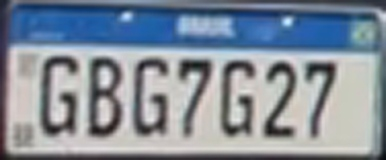

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\prefijos_entregas\ENTREGAS\Jennifer\ProyectoCV\S_ProyectoCV-1_vision_crudo_13961975_Jennifer.json

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\prefijos_entregas\ENTREGAS\Jennifer\ProyectoCV\S_ProyectoCV-video_procesado_13961975_Jennifer.mp4

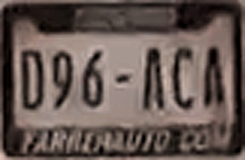

In [11]:
import json
from collections import Counter
from IPython.display import FileLink, Image, display

from functools import lru_cache
from vision_runtime import archivo_de_entrega

@lru_cache(maxsize=4)
def _lector_pdf_recortes(documento):
    from pypdf import PdfReader
    return PdfReader(documento)

def mostrar_recorte(ruta_recorte, directorio=Path('.'), ancho=270):
    ruta_pdf, separador, nombre = str(ruta_recorte).partition('#attachment=')
    if not separador:
        display(Image(filename=str(directorio / ruta_pdf), width=ancho))
        return
    archivo_pdf = (directorio / ruta_pdf).resolve()
    adjuntos = _lector_pdf_recortes(str(archivo_pdf)).attachments
    if nombre not in adjuntos:
        raise FileNotFoundError(f'El adjunto {nombre!r} no está en {archivo_pdf.name}')
    formato = 'jpeg' if Path(nombre).suffix.lower() in {'.jpg', '.jpeg'} else 'png'
    display(Image(data=adjuntos[nombre][0], format=formato, width=ancho))

for nombre in CONFIGURACION:
    identificador = nombre.split('_')[0].split('-')[0]
    sufijo = f'_{identificador}' if len(CONFIGURACION) > 1 else ''
    raiz = Path('resultados') / Path(nombre).stem
    ruta_generada = raiz / 'output/1_vision_crudo.json'
    nuevos_resultados = ruta_generada.is_file()
    json_vision = ruta_generada if nuevos_resultados else archivo_de_entrega(Path(f'1_vision_crudo{sufijo}.json'))
    video = (raiz / 'output/video_procesado.mp4' if nuevos_resultados else
             archivo_de_entrega(Path(f'video_procesado{sufijo}.mp4')))
    base_recortes = raiz if nuevos_resultados else Path('.')
    registros = json.loads(json_vision.read_text(encoding='utf-8'))
    tipos = Counter(fila['tipo_vehiculo'] for fila in registros)
    con_placa = sum(bool(fila['ruta_crop_placa']) for fila in registros)
    con_ocr = sum(bool(fila['texto_ocr_crudo']) for fila in registros)
    print(nombre)
    print(f'Pistas: {len(registros)} | Con recorte de placa: {con_placa} | Con OCR: {con_ocr}')
    print('Tipos detectados:', dict(tipos))
    display(FileLink(json_vision.as_posix()), FileLink(video.as_posix()))
    capturas = []
    if nuevos_resultados:
        evidencias = raiz / 'output/capturas'
        for patron in ('cuadro_*.jpg', '*_antes_*.jpg', '*_despues_*.jpg'):
            capturas.extend(sorted(evidencias.glob(patron))[:1])
    placas = [fila['ruta_crop_placa'] for fila in registros if fila['ruta_crop_placa']]
    for imagen in capturas:
        display(Image(filename=str(imagen), width=540))
    if placas:
        mostrar_recorte(placas[0], base_recortes)


## Evidencias y resultados de prueba

Los ejemplos etiquetados permiten comprobar el modelo con fuentes conocidas. El CSV indica los archivos, las mediciones y el alcance de cada prueba.


Informe de evidencias y JPG originales en el panel Adjuntos
Registros JSON agrupados por prueba
Resultados registrados en la entrega
Verificado · Marca y modelo en cinco fotografías · Toyota Corolla Sedan 2012 89.3% | Honda Accord Sedan 2012 92.8% | Ford F-150 Regular Cab 2012 91.5% | Chevrolet Silverado 1500 Hybrid Crew Cab 2012 93.1% | Volkswagen Golf Hatchback 2012 94.9%
Verificado · Estado de la placa por diseño gráfico · Jalisco → Jalisco (90.3%) | Estado de México → Estado de México (94.7%) | Quintana Roo → Quintana Roo (97.5%)
Parcial · Marca con placa tapada · Secuencia real: ID 1 conserva marca BMW (82% → 64%); OCR visible GBG7G27, cubierto null
Verificado · Fotografía con tres tipos de vehículo · camion: 1 | auto: 6 | motocicleta: 1
Parcial · Sedán, pickup y moto en prueba controlada · sedan: 1 | pickup: 1 | motocicleta: 1
Verificado · Placa trasera de motocicleta · Recorte automático 84 × 59 px · confianza de detección 74.0%
Verificado · Auto en diagonal y corrección de pers

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-Evidencias_Jennifer.pdf

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-Evidencias_JSON_Jennifer.json

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-evidencias_cv_Jennifer.csv

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-control_placa_visible_video_procesado_Jennifer.mp4

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-control_placa_cubierta_video_procesado_Jennifer.mp4

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-cruce_10s_Jennifer.mp4

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-luz_artificial_Jennifer.mp4

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-oclusion_real_Jennifer.mp4

C:\Users\terst\Documents\Codex\2026-11-21\tengo-en-mi-escritorio-una-carpeta\work\json_cv_agrupados\ENTREGAS\Jennifer\ProyectoCV\F_ProyectoCV-trafico_15s_Jennifer.mp4

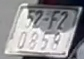

In [12]:
import json
import csv
from pathlib import Path
from IPython.display import FileLink, display

raiz = Path.cwd()
tabla = raiz / 'F_ProyectoCV-evidencias_cv_Jennifer.csv'
if not tabla.is_file():
    tabla = (raiz / 'F_evidencias_cv.csv' if (raiz / 'F_evidencias_cv.csv').is_file() else raiz / 'evidencias_cv.csv')
pdf_entregado = raiz / 'F_ProyectoCV-Evidencias_Jennifer.pdf'
candidatos_pdf = [pdf_entregado] if pdf_entregado.is_file() else sorted(raiz.glob('F_Evidencias_CV_*.pdf'))
informe = next(iter(candidatos_pdf or sorted(raiz.glob('Evidencias_CV_*.pdf'))), None)
if informe:
    print('Informe de evidencias y JPG originales en el panel Adjuntos')
    display(FileLink(informe.name))
ruta_evidencias_json = raiz / 'F_ProyectoCV-Evidencias_JSON_Jennifer.json'
evidencias_json = {}
if ruta_evidencias_json.is_file():
    evidencias_json = json.loads(ruta_evidencias_json.read_text(encoding='utf-8-sig'))['pruebas']
    print('Registros JSON agrupados por prueba')
    display(FileLink(ruta_evidencias_json.name))
if tabla.is_file():
    print('Resultados registrados en la entrega')
    with tabla.open(encoding='utf-8-sig', newline='') as archivo:
        for fila in csv.DictReader(archivo):
            if fila['prueba'] != 'Resultado individual de marca':
                print(f"{fila['estado']} · {fila['prueba']} · {fila['resultado']}")
    display(FileLink(tabla.name))
    videos = []
    with tabla.open(encoding='utf-8-sig', newline='') as archivo:
        for fila in csv.DictReader(archivo):
            videos.extend(ruta for ruta in fila['archivos'].split(' | ') if ruta.endswith('.mp4'))
    for ruta in dict.fromkeys(videos):
        if (raiz / ruta).is_file():
            display(FileLink(ruta))
if not informe and not tabla.is_file():
    print('Los archivos PDF y CSV de evidencia se entregan por separado junto al cuaderno.')

registro_moto = evidencias_json.get('moto_deteccion')
if registro_moto is None:
    for nombre in ('F_moto_deteccion.json', 'moto_deteccion.json'):
        archivo = raiz / nombre
        if archivo.is_file():
            registro_moto = json.loads(archivo.read_text(encoding='utf-8-sig'))
            break
if informe and registro_moto:
    recorte_moto = registro_moto['ruta_crop_placa']
    if recorte_moto:
        print('Recorte original de motocicleta')
        mostrar_recorte(recorte_moto, raiz)


## Revisión complementaria · Longitud y confianza de las lecturas OCR

La longitud cuenta caracteres alfanuméricos en el texto crudo. La confianza es la mediana de las puntuaciones que devolvió el motor.


In [13]:
def revisar_longitud_y_confianza_ocr():
    from pathlib import Path
    from IPython.display import Markdown, display

    def buscar(candidatos):
        return next((Path(nombre) for nombre in candidatos if Path(nombre).is_file()), None)

    def tabla(columnas, filas):
        def celda(valor):
            return str(valor).replace("|", "&#124;").replace("\n", " ")
        def linea(valores):
            return "| " + " | ".join(celda(valor) for valor in valores) + " |"
        encabezado = [linea(columnas), linea(["---"] * len(columnas))]
        display(Markdown("\n".join(encabezado + [linea(fila) for fila in filas])))

    import json
    from collections import Counter, defaultdict

    archivos = {'13961975-uhd_2160_3840_30fps.mp4': 'S_ProyectoCV-1_vision_crudo_13961975_Jennifer.json',
     '16995761_6480_4320_30fps.mp4': 'S_ProyectoCV-1_vision_crudo_16995761_Jennifer.json'}
    pistas = []
    usados = []
    faltantes = []
    for video, nombre in archivos.items():
        generada = Path("resultados") / Path(video).stem / "output" / "1_vision_crudo.json"
        recurso = buscar((generada, nombre))
        if recurso:
            pistas.extend(json.loads(recurso.read_text(encoding="utf-8-sig")))
            usados.append(recurso.name)
        else:
            faltantes.append(nombre)
    if faltantes:
        print("Para recalcular, carga:", ", ".join(faltantes))
        return
    print("Datos analizados:", ", ".join(usados))
    if not pistas:
        print("Los resultados no contienen pistas de vehículos.")
        return

    from statistics import median

    grupos = defaultdict(list)
    orden = ("1 a 4", "5 a 6", "7 o más")
    for r in pistas:
        texto = r.get("texto_ocr_crudo") or ""
        longitud = sum(ch.isalnum() for ch in texto)
        if longitud:
            tramo = orden[0 if longitud <= 4 else 1 if longitud <= 6 else 2]
            grupos[r["fuente"], tramo].append(r.get("confianza_ocr"))
    filas = []
    for video in sorted({r["fuente"] for r in pistas}):
        for tramo in orden:
            lecturas = grupos[video, tramo]
            puntuaciones = [valor for valor in lecturas if valor is not None]
            confianza = f"{median(puntuaciones):.1%}" if puntuaciones else "Sin puntuación"
            filas.append((video, tramo, len(lecturas), confianza))
    tabla(("Video", "Caracteres", "Lecturas", "Confianza mediana"), filas)


revisar_longitud_y_confianza_ocr()


Datos analizados: S_ProyectoCV-1_vision_crudo_13961975_Jennifer.json, S_ProyectoCV-1_vision_crudo_16995761_Jennifer.json


| Video | Caracteres | Lecturas | Confianza mediana |
| --- | --- | --- | --- |
| 13961975-uhd_2160_3840_30fps.mp4 | 1 a 4 | 0 | Sin puntuación |
| 13961975-uhd_2160_3840_30fps.mp4 | 5 a 6 | 4 | 94.5% |
| 13961975-uhd_2160_3840_30fps.mp4 | 7 o más | 1 | 64.0% |
| 16995761_6480_4320_30fps.mp4 | 1 a 4 | 0 | Sin puntuación |
| 16995761_6480_4320_30fps.mp4 | 5 a 6 | 5 | 34.0% |
| 16995761_6480_4320_30fps.mp4 | 7 o más | 4 | 100.0% |

*Para revisar un recorte con calma.* En el clip `16995761`, el grupo de siete caracteres o más tiene cuatro lecturas y una confianza mediana de 100 %. Es un buen punto para abrir una captura y cotejar carácter por carácter. La puntuación pertenece al motor OCR y el recorte permite inspeccionar la lectura.
